# E13-H70 - matched order gap

**Author**: Konrad Jelen (kj) <br>
**Date**: 2026-10-09 <br>
**Pipeline stage**: experiment - E13 campaign, stage A (measure), order axis <br>
**Execution model**: opus <br>

Measures one registered lever on the shipped OPW order gap (`docdistance.distance.opw_gap`, the number behind
`structure_closeness`): compute the order gap over the one-to-one matched statement pairs only, in place of the
two whole documents. E12-H62 measured that the shipped order gap reads an order-preserving deletion as a reorder
(median `0.134` at `k=2`, 280 of 280 cases above the paraphrase reference `0.005`). This notebook measures
whether the matched input set removes that reading while a reordered document still reads as reordered. Nothing
under `src/` is edited: the lever is prototyped here on top of the shipped functions.

**Mechanism under test**. A unit-capacity partial matching pairs each statement of `A` with at most one statement
of `B`, and keeps the pair only when its ground cost `C` is below a cutoff `c`:

$$M^* = \arg\min_{M} \sum_{(i,j) \in M} \min(C_{ij},\, c), \qquad M_c = \{(i,j) \in M^* : C_{ij} < c\}$$

`A'` holds the statements of `A` that appear in `M_c`, in the order they have in `A`; `B'` holds the statements of
`B` that appear in `M_c`, in the order they have in `B`. Unmatched statements leave the order problem, so `A'` and
`B'` have equal length and uniform marginals, and the diagonal coupling is feasible whenever the order was kept.
The reading is the shipped function on the two sub-sequences:

$$g_c(A, B) = g(A', B'), \qquad g(X, Y) = \max\big(0,\ \langle T_{\mathrm{OPW}}(X, Y),\, C(X, Y) \rangle - \mathrm{SMD}(X, Y)\big)$$

`g` is the shipped `opw_gap`. It is a score, not a metric, and `g_c` is a score as well.

## Approach
1. **Kill-gate** - `opw_gap(B, B)` on the 10 base documents - an identity floor above `0.005` makes the bar unreachable
2. **Harness sanity check** - rebuild the 280 E12-H62 deletion cases and reproduce the shipped median `0.134` at `k=2` - the lever must be scored on the registered set
3. **Clause 1** - share of the 280 deletion cases that read `≤ 0.005` under `g_c` - bar `≥ 95%`
4. **Clause 2** - deleted-only against reordered-and-deleted cases (E11 rung 2 or above, `k=2`) - bar AUC `≥ 0.95`
5. **Clause 3** - exact equality with shipped `opw_gap` on every fully matched equal-length pair of the structure fixture; the unequal-length fixture pairs are tabulated without a bar
6. **Prediction and sensitivity** - retention of the reorder rung under two rules; cutoffs `0.35` and `0.45` reported without a bar
7. **Second pass** - the cutoff on reworded survivors, outside the registered bar - the registered sets keep the survivors byte-identical, so they cannot exercise the cutoff
8. **Third pass** - order-preserving deletions on the long fixture document `source`, outside the registered bar - the registered documents hold 11 to 14 statements and no repeated statement, so they cannot exercise a tie in the matching or the growth of the identity floor with length
9. **Guardrails** - `V` counted on the ibm panel, source tree hashed, default path compared by exact equality

## Outputs
- `reports/E13-H70-matched-order-gap-metrics.json` - every measured number, the bar readings, the guardrail readings
- In-notebook: the kill-gate table, the sanity table, one table and one figure per clause, the rung table, the second-pass table, the third-pass tables and figure, the conclusions

## Environment

No GPU is used. The campaign primer pins stage A to CPU, so `CUDA_VISIBLE_DEVICES` is set empty before any model
library is imported; the encoder is the shipped OpenVINO INT8 mmBERT and every transport solve is numpy, POT or scipy.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""            # CPU only - set before any torch import
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
print("device: CPU only | encoder backend: OpenVINO INT8 | transport solves: numpy + POT + scipy")

device: CPU only | encoder backend: OpenVINO INT8 | transport solves: numpy + POT + scipy


## Imports

The shipped `docdistance` core (`distance`, `encoders`, the `pipeline` constant), scipy for the assignment solve,
scikit-learn for the AUC, polars for the result tables, rich and matplotlib for the output.

In [2]:
%load_ext autoreload
%autoreload 2

# stdlib
from collections import Counter                     # repeated statement texts
from collections.abc import Iterable                # type of a sequence of statement texts
import hashlib                                      # sha256 of the source tree (src-untouched guardrail)
import json                                         # fixture files and the metrics JSON
import subprocess                                   # git status (src-untouched guardrail)
import sys                                          # interpreter path, progress-bar stream
import warnings                                     # silence third-party deprecation warnings
from pathlib import Path                            # repository paths

warnings.filterwarnings("ignore")

# scientific
import numpy as np                                  # arrays, medians, exact equality checks
import polars as pl                                 # result tables
import scipy                                        # version line
import sklearn                                      # version line
from scipy.optimize import linear_sum_assignment    # unit-capacity statement matching (the lever)
from sklearn.metrics import roc_auc_score           # AUC of the separation clause

# visualisation
import matplotlib.pyplot as plt                     # inline figures

# console
from rich.console import Console, Group             # one output block per result
from rich.panel import Panel                        # bordered verdict blocks
from rich.table import Table                        # tabular readings
from tqdm import tqdm                               # text progress bar for the permutation sweep

# optimal transport and the shipped core
import ot                                           # POT, the solver behind smd and opw_gap
import docdistance                                  # version line
from docdistance.distance import SMD_MAX, cost_matrix, opw_gap, smd   # shipped functions, used unmodified
from docdistance.encoders import Segmenter, load_encoder              # shipped segmenter and INT8 encoder
from docdistance.pipeline import NO_COUNTERPART_COST                  # 0.6, the registered cutoff

console = Console()
console.print(
    f"[bold medium_purple]Imports ready[/bold medium_purple]\n"
    f"  python [dark_sea_green]{sys.version.split()[0]}[/dark_sea_green] [dim]{sys.executable}[/dim]\n"
    f"  docdistance [dark_sea_green]{docdistance.__version__}[/dark_sea_green] | POT [dark_sea_green]{ot.__version__}[/dark_sea_green]"
    f" | numpy [dark_sea_green]{np.__version__}[/dark_sea_green] | scipy [dark_sea_green]{scipy.__version__}[/dark_sea_green]"
    f" | scikit-learn [dark_sea_green]{sklearn.__version__}[/dark_sea_green] | polars [dark_sea_green]{pl.__version__}[/dark_sea_green]"
)

Imports ready
  python 3.14.8 /home/lab/workspace/learning/projects/docdistance/.venv/bin/python
  docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6 | scipy 1.17.1 | scikit-learn 1.9.0 | polars 1.42.1

## Reproducibility

`SEED = 0` is the E12-H62 seed. The interior-deletion draws use `np.random.default_rng([SEED, base index, k, rep])`,
so this value is what makes the rebuilt deletion set identical to the E12-H62 set. Every other computation is
deterministic: the encoder is a frozen INT8 graph and the three solvers (fixed-iteration Sinkhorn, network simplex,
assignment) take no random input.

In [3]:
SEED = 0
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=0


## Configuration

Paths, the registered bars of the E13-H70 record, the E12-H62 deletion grid, the E11 rung definition and the figure
palette. The record gives no number for the harness sanity tolerance and none for "near its reorder rung": both are
executor readings, written in this cell. The notebook was executed more than once, so the repository does not prove
that either was chosen before the readings were seen. The rung result is therefore reported under two rules.

- **Sanity tolerance** - the rebuilt shipped median at `k=2` must sit within `0.0005` of the saved E12-H62 value, which reproduces `0.134` at the three decimals the record quotes
- **E11 rung** - E11 bins the normalized footrule displacement of a permutation into 6 equal-width bins; rung 2 is the bin `[1/6, 2/6)`, so "at or above rung 2" is displacement `≥ 1/6`
- **Rung retention, executor rule** - a rung `r` is retained when the median matched gap of its reordered-and-deleted cases lies strictly between the reorder-only medians of rungs `r-1` and `r+1` (no upper limit for rung 6). The rule is wide, so it is also applied to the shipped medians as a control that it can fail
- **Rung retention, nearest-median rule** - a rung `r` is retained when the reorder-only median nearest to its matched median is the median of rung `r` itself
- **Third pass** - prefixes of the fixture document `source`, 2 interior deletions, 20 draws per length, each draw seeded `[7, prefix length, draw]` as in the stage A verifier probe that this pass reproduces

In [4]:
# Paths
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
FIXTURE = ROOT / "data/processed/structure-fixture"                      # 10 base documents, reorder pool, pairs
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"   # ibm panel for the V guardrail
H62_METRICS = ROOT / "reports/E12-H62-order-gap-length-residual-metrics.json"  # saved shipped readings
METRICS_OUT = ROOT / "reports/E13-H70-matched-order-gap-metrics.json"

# Registered bars (E13-H70 record, applied literally)
GAP_BAR = 0.005                        # paraphrase reference p95: kill-gate ceiling and deletion ceiling
DELETION_SHARE_BAR = 0.95              # share of the 280 deletion cases that must read <= GAP_BAR
AUC_BAR = 0.95                         # deleted-only against reordered-and-deleted
C_REGISTERED = NO_COUNTERPART_COST     # 0.6, the registered arm
C_SENSITIVITY = (0.35, 0.45)           # reported without a bar
CUTOFFS = (*C_SENSITIVITY, C_REGISTERED)

# E12-H62 deletion set, rebuilt exactly
KS = (1, 2, 3, 4)                      # statements deleted
INTERIOR_REPS = 5                      # interior draws per base and k
K_SEPARATION = 2                       # deletion depth of the separation clause

# Harness sanity check - the tolerance is an executor value, the record gives none
H62_MEDIAN_K2 = 0.134                  # the shipped reading the record quotes
SANITY_TOL = 5e-4                      # absolute tolerance on the saved k=2 median

# E11 scramble ladder
N_RUNGS = 6                            # equal-width bins of the normalized footrule displacement
RUNG_EDGES = np.linspace(0.0, 1.0, N_RUNGS + 1)
RUNG_MIN = 2                           # "at or above the E11 rung-2 level"

# Third pass, outside the registered bar: order-preserving deletions on the long fixture document
LONG_DOC = "source"                    # the one structure-fixture document above 14 statements
LONG_PREFIXES = (14, 20, 30, 40, 50)   # prefix lengths; the whole document is appended as the last length
LONG_REPS = 20                         # interior draws per prefix length
LONG_K = 2                             # statements deleted per draw
LONG_SEED = 7                          # seed head of the verifier probe this pass reproduces: [7, n, draw]

# ibm panel for the V guardrail: (file, label, tier), reference first
PANEL_DOCS = [
    ("exec-summary-gold-opus-4-6.md", "gold", "gold"),
    ("exec-summary-gold-2-opus-4-6.md", "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md", "v1", "gold"),
    ("exec-summary-2-opus-4-6.md", "v2", "gold"),
    ("exec-summary-opus-4-6.md", "opus", "gold"),
    ("exec-summary-sonnet-4-6.md", "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md", "haiku", "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md", "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md", "adv2-b", "adv2"),
]
PANEL_REFERENCE = "gold"
PANEL_PRIMER_ROW = {"V": 0, "margin_pts": 4.71}    # naive row on OpenVINO INT8 quoted by the campaign primer

# Figure palette: one colour per series for the whole notebook
COL_SHIPPED = "#E74C3C"                # shipped opw_gap(A, B)
COL_MATCHED = "#3498DB"                # matched order gap g_c(A, B)
COL_REORDER = "#2ECC71"                # shipped opw_gap on reorder-only pairs
COL_REFERENCE = "#7F8C8D"              # bars and reference lines
PLOT_FLOOR = 1e-9                      # log-axis floor; smaller readings are drawn at this value


def tag(c: float) -> str:
    """Column suffix of a cutoff, e.g. ``0.6`` → ``c060``."""
    return f"c{round(c * 100):03d}"


REG = f"matched_{tag(C_REGISTERED)}"   # column of the registered arm

console.print(
    f"[bold medium_purple]Configuration[/bold medium_purple]\n"
    f"[dim]{'─' * 60}[/dim]\n"
    f"[bold]Paths[/bold]\n"
    f"  Fixture: [dim]{FIXTURE.relative_to(ROOT)}[/dim]\n"
    f"  E12-H62 metrics: [dim]{H62_METRICS.relative_to(ROOT)}[/dim]\n"
    f"  Output: [cadet_blue]{METRICS_OUT.relative_to(ROOT)}[/cadet_blue]\n\n"
    f"[bold]Registered bars[/bold]\n"
    f"  Kill-gate: opw_gap(B, B) <= [dark_sea_green]{GAP_BAR}[/dark_sea_green] on every base document\n"
    f"  Clause 1: >= [dark_sea_green]{DELETION_SHARE_BAR:.0%}[/dark_sea_green] of the deletion cases read <= [dark_sea_green]{GAP_BAR}[/dark_sea_green]\n"
    f"  Clause 2: AUC >= [dark_sea_green]{AUC_BAR}[/dark_sea_green], deleted-only against reordered-and-deleted (rung >= {RUNG_MIN}, k={K_SEPARATION})\n"
    f"  Clause 3: np.array_equal with shipped opw_gap on every fully matched equal-length fixture pair\n\n"
    f"[bold]Lever[/bold]\n"
    f"  Registered cutoff c: [dark_sea_green]{C_REGISTERED}[/dark_sea_green] [dim](NO_COUNTERPART_COST)[/dim]\n"
    f"  Sensitivity cutoffs: [dark_sea_green]{', '.join(str(c) for c in C_SENSITIVITY)}[/dark_sea_green] [dim](no bar)[/dim]\n\n"
    f"[bold]Deletion set[/bold]\n"
    f"  k: [dark_sea_green]{KS}[/dark_sea_green] | positions: head, tail, interior x{INTERIOR_REPS} | seed [dark_sea_green]{SEED}[/dark_sea_green]\n\n"
    f"[bold]Sanity check[/bold]\n"
    f"  Shipped median at k=2: [dark_sea_green]{H62_MEDIAN_K2}[/dark_sea_green] within [dark_sea_green]{SANITY_TOL}[/dark_sea_green] of the saved E12-H62 value\n\n"
    f"[bold]E11 rungs[/bold]\n"
    f"  Displacement edges: [dark_sea_green]{', '.join(f'{e:.3f}' for e in RUNG_EDGES)}[/dark_sea_green]\n\n"
    f"[bold]Third pass (no bar)[/bold]\n"
    f"  Document: [dark_sea_green]{LONG_DOC}[/dark_sea_green] | prefixes [dark_sea_green]{LONG_PREFIXES}[/dark_sea_green] and the whole document"
    f" | k = [dark_sea_green]{LONG_K}[/dark_sea_green], interior x{LONG_REPS} | seed head [dark_sea_green]{LONG_SEED}[/dark_sea_green]\n\n"
    f"[bold]Device[/bold]\n"
    f"  Using: [green]cpu[/green] [dim](CUDA_VISIBLE_DEVICES empty)[/dim]"
)

Configuration
────────────────────────────────────────────────────────────
Paths
  Fixture: data/processed/structure-fixture
  E12-H62 metrics: reports/E12-H62-order-gap-length-residual-metrics.json
  Output: reports/E13-H70-matched-order-gap-metrics.json

Registered bars
  Kill-gate: opw_gap(B, B) <= 0.005 on every base document
  Clause 1: >= 95% of the deletion cases read <= 0.005
  Clause 2: AUC >= 0.95, deleted-only against reordered-and-deleted (rung >= 2, k=2)
  Clause 3: np.array_equal with shipped opw_gap on every fully matched equal-length fixture pair

Lever
  Registered cutoff c: 0.6 (NO_COUNTERPART_COST)
  Sensitivity cutoffs: 0.35, 0.45 (no bar)

Deletion set
  k: (1, 2, 3, 4) | positions: head, tail, interior x5 | seed 0

Sanity check
  Shipped median at k=2: 0.134 within 0.0005 of the saved E12-H62 value

E11 rungs
  Displacement edges: 0.000, 0.167, 0.333, 0.500, 0.667, 0.833, 1.000

Third pass (no bar)
  Document: source | prefixes (14, 20, 30, 40, 50) and the whole document | k = 2, interior x20 | seed head 7

Device
  Using: cpu (CUDA_VISIBLE_DEVICES empty)

## Fixture load and encode

The structure fixture stores statements, not embeddings. Every one of its 25 documents is encoded once with the
shipped OpenVINO INT8 mmBERT encoder, which is the same statement cloud `opw_gap` and `smd` consume in the library.

In [5]:
META = json.loads((FIXTURE / "meta.json").read_text())
STATEMENTS = json.loads((FIXTURE / "statements.json").read_text())
PAIRS = json.loads((FIXTURE / "pairs.json").read_text())
REORDER = json.loads((FIXTURE / "reorder_pool.json").read_text())
BASES = META["base_docs"]

ENC = load_encoder("openvino", offline=True)
EMB = {label: ENC.encode(doc["statements"]) for label, doc in STATEMENTS.items()}


def repeated_count(texts: Iterable[str]) -> int:
    """Number of entries of ``texts`` whose text occurs more than once among them."""
    return sum(n for n in Counter(texts).values() if n > 1)


REPEATED_IN_BASES = sum(repeated_count(STATEMENTS[base]["statements"]) for base in BASES)
REPEATED_IN_PARAPHRASES = sum(repeated_count(STATEMENTS[f"{base}~bt"]["statements"]) for base in BASES)

t = Table(title=f"Encoded documents - {len(EMB)} in total, the {len(BASES)} base documents listed", header_style="bold medium_purple")
for column in ("base", "statements", "repeated statements", "dim", "article", "reorder-pool entries"):
    t.add_column(column, justify="left" if column in ("base", "article") else "right")
for base in BASES:
    t.add_row(base, str(len(EMB[base])), str(repeated_count(STATEMENTS[base]["statements"])), str(EMB[base].shape[1]),
              STATEMENTS[base]["article"], str(len(REORDER[base])))
console.print(Group(t,
    f"statements whose text occurs more than once in their document: {REPEATED_IN_BASES} in the {len(BASES)} base documents,"
    f" {REPEATED_IN_PARAPHRASES} in their {len(BASES)} back-translation paraphrases"))

            Encoded documents - 25 in total, the 10 base documents listed             
┏━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ base   ┃ statements ┃ repeated statements ┃ dim ┃ article   ┃ reorder-pool entries ┃
┡━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ gold   │         11 │                   0 │ 768 │ ibm       │                  182 │
│ gold-2 │         13 │                   0 │ 768 │ ibm       │                  182 │
│ v1     │         12 │                   0 │ 768 │ ibm       │                  182 │
│ v2     │         12 │                   0 │ 768 │ ibm       │                  182 │
│ opus   │         13 │                   0 │ 768 │ ibm       │                  182 │
│ sonnet │         11 │                   0 │ 768 │ ibm       │                  182 │
│ haiku  │         14 │                   0 │ 768 │ ibm       │                  182 │
│ werg-a │         11 │                   0 │ 768 │ wergeland │                  182 │
│ werg-b │         13 │                   0 │ 768 │ wergeland │                  182 │
│ werg-c │         14 │                   0 │ 768 │ wergeland │                  182 │
└────────┴────────────┴─────────────────────┴─────┴───────────┴──────────────────────┘
statements whose text occurs more than once in their document: 0 in the 10 base documents, 0 in their 10 
back-translation paraphrases

## Guardrail baseline

Recorded before any measurement, so that the closing guardrail section compares against it: one sha256 over every
`.py` file under `src/` and under `tests/`, and the default-path `smd` and `opw_gap` on the pair `(gold, gold-2)`.

In [6]:
def tree_digest(folder: str) -> str:
    """One sha256 over the path and bytes of every ``.py`` file under ``folder``, in sorted path order."""
    digest = hashlib.sha256()
    for path in sorted((ROOT / folder).rglob("*.py")):
        digest.update(str(path.relative_to(ROOT)).encode())
        digest.update(path.read_bytes())
    return digest.hexdigest()


GUARD_FOLDERS = ("src", "tests")
GUARD_PAIR = ("gold", "gold-2")
digest_before = {folder: tree_digest(folder) for folder in GUARD_FOLDERS}
guard_before = np.array([smd(EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]]), opw_gap(EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]])])

console.print(
    f"[bold medium_purple]Guardrail baseline[/bold medium_purple]\n"
    f"  default path on {GUARD_PAIR}: smd [dark_sea_green]{float(guard_before[0])!r}[/dark_sea_green]"
    f" | order gap [dark_sea_green]{float(guard_before[1])!r}[/dark_sea_green]\n"
    + "\n".join(f"  sha256 {folder}/**/*.py: [dim]{digest[:16]}[/dim]" for folder, digest in digest_before.items())
)

Guardrail baseline
  default path on ('gold', 'gold-2'): smd 0.22343884174015136 | order gap 0.1343654387715936
  sha256 src/**/*.py: be7e159f81c53284
  sha256 tests/**/*.py: 00ea6c7799307adb

## Kill-gate

The registered gate: `opw_gap(B, B)` on each of the 10 base documents. The matched gap of an order-preserving
deletion is the order gap of a document against a copy of itself, so if this identity floor exceeds `0.005` the
lever cannot meet clause 1. A second column reads the same pair with the second argument passed as a copy: POT sets
the diagonal of the ground cost to exactly zero only when both arguments are the same object, and the lever always
passes two distinct arrays. The gate is read as registered, on the 10 base documents; it therefore covers their
lengths only, and the third pass reads the same floor on a longer document.

In [7]:
gate_df = pl.DataFrame(
    [
        {
            "base": base,
            "n": len(EMB[base]),
            "identity_gap": opw_gap(EMB[base], EMB[base]),
            "identity_gap_copy": opw_gap(EMB[base], EMB[base].copy()),
        }
        for base in BASES
    ]
)
KILL_GATE_MAX = float(gate_df["identity_gap"].max())
KILL_GATE_MAX_COPY = float(gate_df["identity_gap_copy"].max())
KILL_GATE_PASSED = bool(KILL_GATE_MAX <= GAP_BAR)
GATE_N_MIN, GATE_N_MAX = int(gate_df["n"].min()), int(gate_df["n"].max())

t = Table(title="Kill-gate - opw_gap(B, B) on the 10 base documents", header_style="bold medium_purple")
for column in ("base", "n", "opw_gap(B, B)", "opw_gap(B, copy of B)", f"share of the bar {GAP_BAR}"):
    t.add_column(column, justify="left" if column == "base" else "right")
for row in gate_df.iter_rows(named=True):
    t.add_row(row["base"], str(row["n"]), f"{row['identity_gap']:.3e}", f"{row['identity_gap_copy']:.3e}",
              f"{row['identity_gap'] / GAP_BAR:.2%}")
t.add_row("max", "", f"{KILL_GATE_MAX:.3e}", f"{KILL_GATE_MAX_COPY:.3e}", f"{KILL_GATE_MAX / GAP_BAR:.2%}", style="bold")
gate_colour = "dark_sea_green" if KILL_GATE_PASSED else "indian_red"
console.print(Group(t, Panel(
    f"[bold {gate_colour}]{'GATE PASSED - the experiment proceeds' if KILL_GATE_PASSED else 'GATE FIRED - verdict Killed-at-gate'}[/bold {gate_colour}]"
    f"\nmax opw_gap(B, B) = {KILL_GATE_MAX:.3e} against the ceiling {GAP_BAR}"
    f"\nlengths covered by the gate: {GATE_N_MIN} to {GATE_N_MAX} statements",
    border_style=gate_colour, expand=False)))

               Kill-gate - opw_gap(B, B) on the 10 base documents               
┏━━━━━━━━┳━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ base   ┃  n ┃ opw_gap(B, B) ┃ opw_gap(B, copy of B) ┃ share of the bar 0.005 ┃
┡━━━━━━━━╇━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold   │ 11 │     1.616e-04 │             1.619e-04 │                  3.23% │
│ gold-2 │ 13 │     5.372e-04 │             5.386e-04 │                 10.74% │
│ v1     │ 12 │     3.055e-04 │             3.067e-04 │                  6.11% │
│ v2     │ 12 │     3.569e-04 │             3.577e-04 │                  7.14% │
│ opus   │ 13 │     4.585e-04 │             4.597e-04 │                  9.17% │
│ sonnet │ 11 │     1.860e-04 │             1.865e-04 │                  3.72% │
│ haiku  │ 14 │     8.583e-04 │             8.602e-04 │                 17.17% │
│ werg-a │ 11 │     1.693e-04 │             1.698e-04 │                  3.39% │
│ werg-b │ 13 │     3.801e-04 │             3.808e-04 │                  7.60% │
│ werg-c │ 14 │     7.916e-04 │             7.937e-04 │                 15.83% │
│ max    │    │     8.583e-04 │             8.602e-04 │                 17.17% │
└────────┴────┴───────────────┴───────────────────────┴────────────────────────┘
╭─────────────────────────────────────────────────────────╮
│ GATE PASSED - the experiment proceeds                   │
│ max opw_gap(B, B) = 8.583e-04 against the ceiling 0.005 │
│ lengths covered by the gate: 11 to 14 statements        │
╰─────────────────────────────────────────────────────────╯

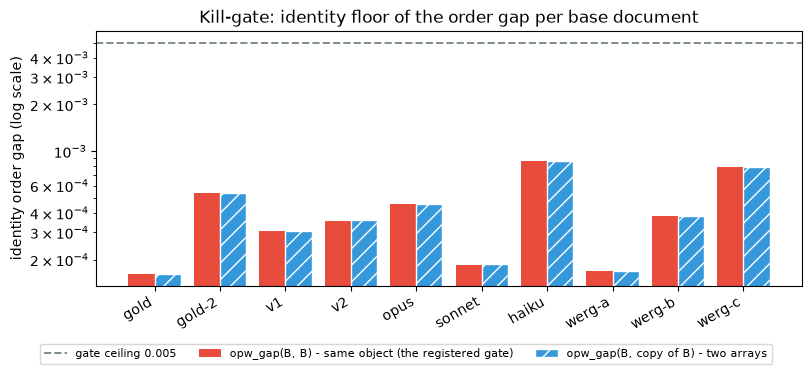

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
x = np.arange(len(BASES))
ax.bar(x - 0.2, gate_df["identity_gap"].to_numpy(), width=0.4, color=COL_SHIPPED,
       label="opw_gap(B, B) - same object (the registered gate)")
ax.bar(x + 0.2, gate_df["identity_gap_copy"].to_numpy(), width=0.4, color=COL_MATCHED, hatch="//",
       edgecolor="white", label="opw_gap(B, copy of B) - two arrays")
ax.axhline(GAP_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"gate ceiling {GAP_BAR}")
ax.set_yscale("log")
ax.set_xticks(x, BASES, rotation=30, ha="right")
ax.set_ylabel("identity order gap (log scale)")
ax.set_title("Kill-gate: identity floor of the order gap per base document")
fig.legend(fontsize=8, loc="outside lower center", ncol=3)
plt.show()

## Harness sanity check - rebuild the E12-H62 deletion set

The 280 order-preserving deletion cases are rebuilt with the E12-H62 code: `delete_positions` is copied verbatim,
the loop order is base → `k` → (head, tail, 5 interior draws), and each draw is seeded with
`[SEED, base index, k, rep]`. The shipped `opw_gap(A, A minus k statements)` is then compared with the per-`k`
medians saved in the E12-H62 metrics JSON. The lever is scored only if the `k=2` median reproduces.

In [9]:
def delete_positions(n: int, k: int, family: str, rng: np.random.Generator) -> list[int]:
    """Indices to drop (E12-H62, verbatim); the surviving indices stay in ascending order."""
    if family == "head":
        return list(range(k))
    if family == "tail":
        return list(range(n - k, n))
    return sorted(rng.choice(np.arange(1, n - 1), size=k, replace=False).tolist())


def deletion_plans(base_index: int, n: int, k: int) -> list[dict]:
    """The 7 E12-H62 deletion plans of one base at depth ``k``: head, tail and 5 interior draws."""
    plans = []
    for family, rep in [("head", 0), ("tail", 0)] + [("interior", r) for r in range(INTERIOR_REPS)]:
        rng = np.random.default_rng([SEED, base_index, k, rep])
        drop = delete_positions(n, k, family, rng)
        plans.append({"family": family, "rep": rep, "keep": [i for i in range(n) if i not in drop]})
    return plans


CASES = [
    {"base": base, "k": k, **plan}
    for base_index, base in enumerate(BASES)
    for k in KS
    for plan in deletion_plans(base_index, len(EMB[base]), k)
]
shipped_deletion = np.array([opw_gap(EMB[case["base"]], EMB[case["base"]][case["keep"]]) for case in CASES])
del_df = pl.DataFrame(
    {
        "base": [case["base"] for case in CASES],
        "k": [case["k"] for case in CASES],
        "family": [case["family"] for case in CASES],
        "rep": [case["rep"] for case in CASES],
        "n_a": [len(EMB[case["base"]]) for case in CASES],
        "n_b": [len(case["keep"]) for case in CASES],
        "shipped": shipped_deletion,
    }
)
print(f"{del_df.height} deletion cases | {del_df['base'].n_unique()} bases | k {sorted(del_df['k'].unique().to_list())}")

280 deletion cases | 10 bases | k [1, 2, 3, 4]


In [10]:
h62_per_k = json.loads(H62_METRICS.read_text())["sweep"]["per_k"]
sanity_rows = []
for k in KS:
    sub = del_df.filter(pl.col("k") == k)["shipped"]
    sanity_rows.append({"k": k, "n": sub.len(), "median_here": float(sub.median()), "median_h62": h62_per_k[str(k)]["median"],
                        "min_here": float(sub.min()), "min_h62": h62_per_k[str(k)]["min"],
                        "max_here": float(sub.max()), "max_h62": h62_per_k[str(k)]["max"]})
sanity_df = pl.DataFrame(sanity_rows)

SHIPPED_MEDIAN_K2 = float(sanity_df.filter(pl.col("k") == 2)["median_here"][0])
SANITY_DEV_K2 = abs(SHIPPED_MEDIAN_K2 - float(h62_per_k["2"]["median"]))
SANITY_MAX_DEV = float(max(
    np.abs(sanity_df[f"{stat}_here"].to_numpy() - sanity_df[f"{stat}_h62"].to_numpy()).max() for stat in ("median", "min", "max")
))
SHIPPED_ABOVE_BAR = int((del_df["shipped"] > GAP_BAR).sum())
SANITY_PASSED = bool(
    del_df.height == 280
    and SANITY_DEV_K2 <= SANITY_TOL
    and round(SHIPPED_MEDIAN_K2, 3) == H62_MEDIAN_K2
    and SHIPPED_ABOVE_BAR == del_df.height
)

t = Table(title="Harness sanity check - shipped opw_gap on the rebuilt deletion set against E12-H62", header_style="bold medium_purple")
for column in ("k", "n", "median here", "median E12-H62", "|dev|", "min here", "min E12-H62", "max here", "max E12-H62"):
    t.add_column(column, justify="right")
for row in sanity_df.iter_rows(named=True):
    t.add_row(str(row["k"]), str(row["n"]), f"{row['median_here']:.6f}", f"{row['median_h62']:.6f}",
              f"{abs(row['median_here'] - row['median_h62']):.1e}", f"{row['min_here']:.6f}", f"{row['min_h62']:.6f}",
              f"{row['max_here']:.6f}", f"{row['max_h62']:.6f}")
sanity_colour = "dark_sea_green" if SANITY_PASSED else "indian_red"
console.print(Group(t, Panel(
    f"[bold {sanity_colour}]{'SANITY CHECK PASSED' if SANITY_PASSED else 'SANITY CHECK FAILED - verdict Blocked'}[/bold {sanity_colour}]\n"
    f"shipped median at k=2: {SHIPPED_MEDIAN_K2:.6f} (record: {H62_MEDIAN_K2}; saved: {h62_per_k['2']['median']}; |dev| {SANITY_DEV_K2:.1e}, tolerance {SANITY_TOL})\n"
    f"largest |dev| over the 12 saved median / min / max values: {SANITY_MAX_DEV:.1e}\n"
    f"cases above the paraphrase reference {GAP_BAR}: {SHIPPED_ABOVE_BAR}/{del_df.height}",
    border_style=sanity_colour, expand=False)))

         Harness sanity check - shipped opw_gap on the rebuilt deletion set against E12-H62          
┏━━━┳━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ k ┃  n ┃ median here ┃ median E12-H62 ┃   |dev| ┃ min here ┃ min E12-H62 ┃ max here ┃ max E12-H62 ┃
┡━━━╇━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ 1 │ 70 │    0.071645 │       0.071645 │ 3.9e-07 │ 0.055093 │    0.055093 │ 0.114415 │    0.114415 │
│ 2 │ 70 │    0.134041 │       0.134041 │ 1.3e-07 │ 0.057359 │    0.057359 │ 0.233079 │    0.233079 │
│ 3 │ 70 │    0.121486 │       0.121486 │ 4.1e-07 │ 0.041979 │    0.041979 │ 0.276171 │    0.276171 │
│ 4 │ 70 │    0.155277 │       0.155277 │ 9.6e-08 │ 0.017529 │    0.017529 │ 0.280982 │    0.280982 │
└───┴────┴─────────────┴────────────────┴─────────┴──────────┴─────────────┴──────────┴─────────────┘
╭───────────────────────────────────────────────────────────────────────────────────────────────────╮
│ SANITY CHECK PASSED                                                                               │
│ shipped median at k=2: 0.134041 (record: 0.134; saved: 0.134041; |dev| 1.3e-07, tolerance 0.0005) │
│ largest |dev| over the 12 saved median / min / max values: 4.9e-07                                │
│ cases above the paraphrase reference 0.005: 280/280                                               │
╰───────────────────────────────────────────────────────────────────────────────────────────────────╯

## The lever - matched order gap

The prototype, built only from shipped functions and `scipy.optimize.linear_sum_assignment`. `match_statements`
solves the assignment on `min(C, c)` and discards pairs at cost `≥ c`; `matched_opw_gap` calls shipped `opw_gap` on
the two matched sub-sequences. When every statement of both documents is matched the sub-sequences are the
documents themselves, so the shipped function receives the unmodified inputs - this keeps the same-object case of
the ground cost and is what makes clause 3 hold on identity pairs.

In [11]:
def match_statements(A: np.ndarray, B: np.ndarray, c: float) -> tuple[np.ndarray, np.ndarray]:
    """Unit-capacity partial matching of the statements of ``A`` and ``B`` at cutoff ``c``.

    Solves the assignment problem on ``min(cost, c)`` and discards every pair whose ground cost is at
    or above ``c``. Returns the matched pairs as two index arrays: pair ``p`` joins statement
    ``rows[p]`` of ``A`` with statement ``cols[p]`` of ``B``.
    """
    cost = cost_matrix(A, B)
    rows, cols = linear_sum_assignment(np.minimum(cost, c))
    kept = cost[rows, cols] < c
    return rows[kept], cols[kept]


def matched_opw_gap(A: np.ndarray, B: np.ndarray, c: float) -> tuple[float, int]:
    """Shipped ``opw_gap`` over the matched sub-sequences; returns ``(gap, matched pairs)``.

    A score, not a metric. Each side keeps its own document order: the matched indices are sorted
    ascending before the sub-sequences are taken. The gap is ``nan`` when no pair is matched. A fully
    matched equal-length pair is passed to ``opw_gap`` unmodified, so its value is the shipped value.
    """
    rows, cols = match_statements(A, B, c)
    if len(rows) == 0:
        return float("nan"), 0
    if len(rows) == len(A) == len(B):
        return opw_gap(A, B), len(rows)
    return opw_gap(A[np.sort(rows)], B[np.sort(cols)]), len(rows)


def survivors_recovered(rows: np.ndarray, cols: np.ndarray, keep: list[int]) -> bool:
    """True when the matching of ``A`` with ``A[keep]`` pairs every surviving statement with its own copy."""
    return bool(len(rows) == len(keep) and np.array_equal(rows, np.asarray(keep)[cols]))


def score_case(A: np.ndarray, B: np.ndarray) -> dict:
    """Shipped gap, then the matched gap and the matched-pair count at every cutoff."""
    out = {"shipped": opw_gap(A, B)}
    for c in CUTOFFS:
        out[f"matched_{tag(c)}"], out[f"n_matched_{tag(c)}"] = matched_opw_gap(A, B, c)
    return out


print("lever defined: match_statements, matched_opw_gap, survivors_recovered, score_case | cutoffs", CUTOFFS)

lever defined: match_statements, matched_opw_gap, survivors_recovered, score_case | cutoffs (0.35, 0.45, 0.6)


## Clause 1 - order-preserving deletions

The 280 deletion cases under the matched gap at the registered cutoff `c = 0.6`. The bar is that at least 95% of
them read `≤ 0.005`. `recovered` counts the cases where the matching returns exactly the surviving statements, each
paired with its own copy. The base documents hold no repeated statement, so the zero-cost assignment is unique and
this count has one possible value on the registered set; the third pass reads a document on which it can move.

In [12]:
scored = []
for case in CASES:
    A = EMB[case["base"]]
    B = A[case["keep"]]
    rows, cols = match_statements(A, B, C_REGISTERED)
    reading = score_case(A, B)
    reading.pop("shipped")
    reading["recovered"] = survivors_recovered(rows, cols, case["keep"])
    scored.append(reading)
del_df = del_df.hstack(pl.DataFrame(scored))

DEL_NAN = int(del_df[REG].is_nan().sum())
DEL_WITHIN = int((del_df[REG] <= GAP_BAR).sum())
DEL_SHARE = DEL_WITHIN / del_df.height
DEL_RECOVERED = int(del_df["recovered"].sum())
CLAUSE1_MET = bool(DEL_SHARE >= DELETION_SHARE_BAR)

per_k = (
    del_df.group_by("k")
    .agg(pl.len().alias("n"), pl.col("shipped").median().alias("shipped_median"), pl.col(REG).median().alias("matched_median"),
         pl.col(REG).quantile(0.95).alias("matched_p95"), pl.col(REG).max().alias("matched_max"),
         (pl.col(REG) <= GAP_BAR).sum().alias("within_bar"))
    .sort("k")
)
MATCHED_MEDIAN_K2 = float(per_k.filter(pl.col("k") == 2)["matched_median"][0])

t = Table(title=f"Clause 1 - matched order gap at c = {C_REGISTERED} on the 280 order-preserving deletion cases", header_style="bold medium_purple")
for column in ("k", "n", "shipped median", "matched median", "matched p95", "matched max", f"<= {GAP_BAR}"):
    t.add_column(column, justify="right")
for row in per_k.iter_rows(named=True):
    t.add_row(str(row["k"]), str(row["n"]), f"{row['shipped_median']:.6f}", f"{row['matched_median']:.3e}",
              f"{row['matched_p95']:.3e}", f"{row['matched_max']:.3e}", f"{row['within_bar']}/{row['n']}")
t.add_row("all", str(del_df.height), f"{float(del_df['shipped'].median()):.6f}", f"{float(del_df[REG].median()):.3e}",
          f"{float(del_df[REG].quantile(0.95)):.3e}", f"{float(del_df[REG].max()):.3e}", f"{DEL_WITHIN}/{del_df.height}", style="bold")
c1_colour = "dark_sea_green" if CLAUSE1_MET else "indian_red"
console.print(Group(t, Panel(
    f"[bold {c1_colour}]clause 1 {'MET' if CLAUSE1_MET else 'NOT MET'}[/bold {c1_colour}]: {DEL_WITHIN}/{del_df.height} = {DEL_SHARE:.4f}"
    f" of the cases read <= {GAP_BAR} (bar >= {DELETION_SHARE_BAR})\n"
    f"median at k=2: shipped {SHIPPED_MEDIAN_K2:.6f} → matched {MATCHED_MEDIAN_K2:.3e}\n"
    f"matching recovered exactly the surviving statements in {DEL_RECOVERED}/{del_df.height} cases | cases with no matched pair: {DEL_NAN}\n"
    f"repeated statements in the {len(BASES)} base documents: {REPEATED_IN_BASES} - the zero-cost assignment is unique on this set",
    border_style=c1_colour, expand=False)))

  Clause 1 - matched order gap at c = 0.6 on the 280 order-preserving deletion cases  
┏━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃   k ┃   n ┃ shipped median ┃ matched median ┃ matched p95 ┃ matched max ┃ <= 0.005 ┃
┡━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━┩
│   1 │  70 │       0.071645 │      2.056e-04 │   5.669e-04 │   6.101e-04 │    70/70 │
│   2 │  70 │       0.134041 │      9.671e-05 │   3.485e-04 │   3.632e-04 │    70/70 │
│   3 │  70 │       0.121486 │      3.627e-05 │   1.835e-04 │   1.942e-04 │    70/70 │
│   4 │  70 │       0.155277 │      9.266e-06 │   7.471e-05 │   8.022e-05 │    70/70 │
│ all │ 280 │       0.102628 │      6.734e-05 │   3.632e-04 │   6.101e-04 │  280/280 │
└─────┴─────┴────────────────┴────────────────┴─────────────┴─────────────┴──────────┘
╭──────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 1 MET: 280/280 = 1.0000 of the cases read <= 0.005 (bar >= 0.95)                              │
│ median at k=2: shipped 0.134041 → matched 9.671e-05                                                  │
│ matching recovered exactly the surviving statements in 280/280 cases | cases with no matched pair: 0 │
│ repeated statements in the 10 base documents: 0 - the zero-cost assignment is unique on this set     │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────╯

The figure shows every deletion case twice: the shipped order gap (circles) and the matched order gap (squares),
per deletion depth `k`, against the registered ceiling. The reading to check is on which side of the dashed line
each series lies.

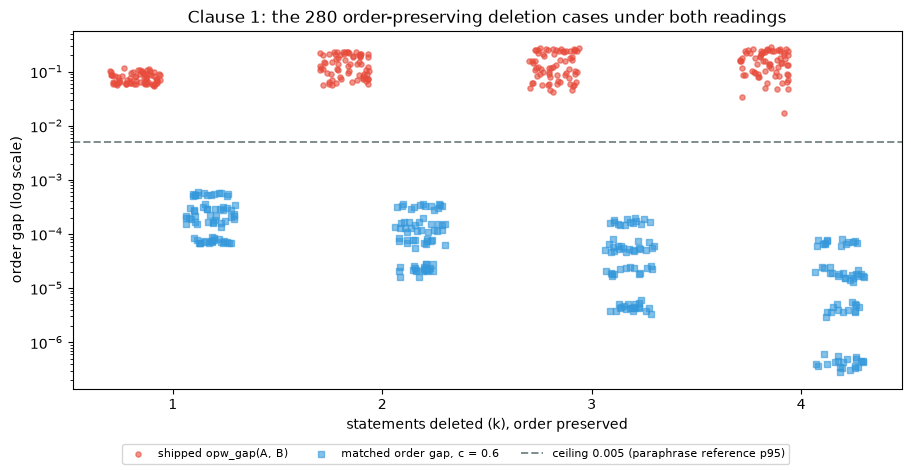

In [13]:
rng_plot = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(9, 4.6), constrained_layout=True)
for offset, column, colour, marker, label in (
    (-0.18, "shipped", COL_SHIPPED, "o", "shipped opw_gap(A, B)"),
    (+0.18, REG, COL_MATCHED, "s", f"matched order gap, c = {C_REGISTERED}"),
):
    jitter = rng_plot.uniform(-0.12, 0.12, del_df.height)
    ax.scatter(del_df["k"].to_numpy() + offset + jitter, np.maximum(del_df[column].to_numpy(), PLOT_FLOOR),
               s=14, alpha=0.6, color=colour, marker=marker, label=label)
ax.axhline(GAP_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"ceiling {GAP_BAR} (paraphrase reference p95)")
ax.set_yscale("log")
ax.set_xticks(list(KS))
ax.set_xlabel("statements deleted (k), order preserved")
ax.set_ylabel("order gap (log scale)")
ax.set_title("Clause 1: the 280 order-preserving deletion cases under both readings")
fig.legend(fontsize=8, loc="outside lower center", ncol=3)
plt.show()

## Clause 2 - deleted-only against reordered-and-deleted

The negative class is the 70 deleted-only cases at `k=2`. The positive class takes every unique permutation of the
fixture reorder pool whose displacement is at or above the E11 rung-2 level, applies it to the base document, and
then applies each of the same 7 `k=2` deletion plans to the reordered document - so every positive case has a
negative case with the same drop positions. Rung-1 permutations are scored as well, for the rung table only.
`order_kept` marks a positive case whose surviving statements are still in ascending original order after the deletion.

In [14]:
def rung_of(disp: float) -> int:
    """E11 rung (1 to 6) of a normalized footrule displacement: 6 equal-width bins, top edge closed."""
    return int(min(np.searchsorted(RUNG_EDGES, disp, side="right"), N_RUNGS))


def induced_displacement(survivors: np.ndarray) -> float:
    """Normalized footrule of the order the surviving statements have, relative to their original order."""
    ranks = np.argsort(np.argsort(survivors))
    return float(np.abs(ranks - np.arange(len(ranks))).sum()) / (len(ranks) * len(ranks) // 2)


POOL = []                      # one entry per unique permutation of every base
for base in BASES:
    seen = set()
    for entry in REORDER[base]:
        perm = tuple(entry["perm"])
        if perm not in seen:
            seen.add(perm)
            POOL.append({"base": base, "perm": list(perm), "disp": entry["disp"], "rung": rung_of(entry["disp"])})
PLANS_K2 = {base: deletion_plans(base_index, len(EMB[base]), K_SEPARATION) for base_index, base in enumerate(BASES)}
print(f"{len(POOL)} unique permutations over {len(BASES)} bases (pool entries: {sum(len(v) for v in REORDER.values())})"
      f" | {sum(len(v) for v in PLANS_K2.values())} k={K_SEPARATION} deletion plans")

1611 unique permutations over 10 bases (pool entries: 1820) | 70 k=2 deletion plans


In [15]:
pool_rows, pos_rows = [], []
for item in tqdm(POOL, desc="unique permutations", mininterval=15.0, file=sys.stdout):
    A = EMB[item["base"]]
    Y = A[item["perm"]]
    reorder_only = opw_gap(A, Y)
    pool_rows.append({"base": item["base"], "disp": item["disp"], "rung": item["rung"], "reorder_only": reorder_only})
    for plan in PLANS_K2[item["base"]]:
        survivors = np.asarray(item["perm"])[plan["keep"]]
        pos_rows.append({
            "base": item["base"], "disp": item["disp"], "rung": item["rung"], "family": plan["family"], "rep": plan["rep"],
            "order_kept": bool(np.all(np.diff(survivors) > 0)), "disp_after": induced_displacement(survivors),
            "reorder_only": reorder_only, **score_case(A, Y[plan["keep"]]),
        })
pool_df = pl.DataFrame(pool_rows)
pos_df = pl.DataFrame(pos_rows)

unique permutations:   0%|          | 0/1611 [00:00<?, ?it/s]

unique permutations:  64%|██████▍   | 1032/1611 [00:15<00:08, 68.76it/s]

unique permutations: 100%|██████████| 1611/1611 [00:23<00:00, 68.80it/s]

In [16]:
def auc(negatives: np.ndarray, positives: np.ndarray) -> float:
    """AUC of ``positives`` reading above ``negatives``; a tie counts one half."""
    labels = np.r_[np.zeros(len(negatives)), np.ones(len(positives))]
    return float(roc_auc_score(labels, np.r_[negatives, positives]))


neg_df = del_df.filter(pl.col("k") == K_SEPARATION)
sep_df = pos_df.filter(pl.col("rung") >= RUNG_MIN)
POS_NAN = int(sep_df[REG].is_nan().sum())
assert POS_NAN == 0 and DEL_NAN == 0, "a case with no matched pair has no order gap; the AUC is undefined"

AUC_ROWS = {}
for method in ("shipped", REG):
    neg, pos = neg_df[method].to_numpy(), sep_df[method].to_numpy()
    AUC_ROWS[method] = {
        "auc": auc(neg, pos),
        "auc_all_280_negatives": auc(del_df[method].to_numpy(), pos),
        "auc_excluding_order_kept": auc(neg, sep_df.filter(~pl.col("order_kept"))[method].to_numpy()),
        "per_rung": {r: auc(neg, sep_df.filter(pl.col("rung") == r)[method].to_numpy()) for r in range(RUNG_MIN, N_RUNGS + 1)},
        "neg_max": float(neg.max()), "pos_min": float(pos.min()),
        "pos_min_excluding_order_kept": float(sep_df.filter(~pl.col("order_kept"))[method].min()),
        "pos_at_or_below_bar": int((pos <= GAP_BAR).sum()), "neg_above_bar": int((neg > GAP_BAR).sum()),
    }
AUC_MATCHED = AUC_ROWS[REG]["auc"]
AUC_SHIPPED = AUC_ROWS["shipped"]["auc"]
N_NEG, N_POS = neg_df.height, sep_df.height
N_ORDER_KEPT = int(sep_df["order_kept"].sum())
ORDER_KEPT_AT_OR_BELOW_BAR = int((sep_df.filter(pl.col("order_kept"))[REG] <= GAP_BAR).sum())
CLAUSE2_MET = bool(AUC_MATCHED >= AUC_BAR)

t = Table(title=f"Clause 2 - AUC, {N_NEG} deleted-only (k={K_SEPARATION}) against {N_POS} reordered-and-deleted (rung >= {RUNG_MIN}, k={K_SEPARATION})",
          header_style="bold medium_purple")
for column in ("reading", "shipped opw_gap", f"matched, c = {C_REGISTERED}"):
    t.add_column(column, justify="left" if column == "reading" else "right")
t.add_row("AUC (registered classes)", f"{AUC_SHIPPED:.6f}", f"{AUC_MATCHED:.6f}", style="bold")
t.add_row("AUC, all 280 deletion cases as negatives", f"{AUC_ROWS['shipped']['auc_all_280_negatives']:.6f}", f"{AUC_ROWS[REG]['auc_all_280_negatives']:.6f}")
t.add_row(f"AUC, excluding the {N_ORDER_KEPT} order-kept positives", f"{AUC_ROWS['shipped']['auc_excluding_order_kept']:.6f}", f"{AUC_ROWS[REG]['auc_excluding_order_kept']:.6f}")
for r in range(RUNG_MIN, N_RUNGS + 1):
    t.add_row(f"AUC, rung {r} positives only (n={sep_df.filter(pl.col('rung') == r).height})",
              f"{AUC_ROWS['shipped']['per_rung'][r]:.6f}", f"{AUC_ROWS[REG]['per_rung'][r]:.6f}")
t.add_row("largest deleted-only reading", f"{AUC_ROWS['shipped']['neg_max']:.6f}", f"{AUC_ROWS[REG]['neg_max']:.3e}")
t.add_row("smallest reordered-and-deleted reading", f"{AUC_ROWS['shipped']['pos_min']:.6f}", f"{AUC_ROWS[REG]['pos_min']:.3e}")
t.add_row("smallest reading of a positive that is not order-kept", f"{AUC_ROWS['shipped']['pos_min_excluding_order_kept']:.6f}",
          f"{AUC_ROWS[REG]['pos_min_excluding_order_kept']:.6f}")
t.add_row(f"deleted-only above {GAP_BAR}", f"{AUC_ROWS['shipped']['neg_above_bar']}/{N_NEG}", f"{AUC_ROWS[REG]['neg_above_bar']}/{N_NEG}")
t.add_row(f"reordered-and-deleted at or below {GAP_BAR}", f"{AUC_ROWS['shipped']['pos_at_or_below_bar']}/{N_POS}", f"{AUC_ROWS[REG]['pos_at_or_below_bar']}/{N_POS}")
c2_colour = "dark_sea_green" if CLAUSE2_MET else "indian_red"
console.print(Group(t, Panel(
    f"[bold {c2_colour}]clause 2 {'MET' if CLAUSE2_MET else 'NOT MET'}[/bold {c2_colour}]: AUC {AUC_MATCHED:.6f} (bar >= {AUC_BAR}); shipped baseline {AUC_SHIPPED:.6f}\n"
    f"positives whose survivors are still in original order after the deletion: {N_ORDER_KEPT}/{N_POS}, of which {ORDER_KEPT_AT_OR_BELOW_BAR} read <= {GAP_BAR} under the matched gap",
    border_style=c2_colour, expand=False)))

  Clause 2 - AUC, 70 deleted-only (k=2) against 10010 reordered-and-deleted (rung >= 2, k=2)  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ reading                                               ┃ shipped opw_gap ┃ matched, c = 0.6 ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ AUC (registered classes)                              │        0.950980 │         0.999903 │
│ AUC, all 280 deletion cases as negatives              │        0.945924 │         0.999925 │
│ AUC, excluding the 1 order-kept positives             │        0.951075 │         1.000000 │
│ AUC, rung 2 positives only (n=1904)                   │        0.818067 │         0.999490 │
│ AUC, rung 3 positives only (n=2191)                   │        0.945022 │         1.000000 │
│ AUC, rung 4 positives only (n=2905)                   │        0.992338 │         1.000000 │
│ AUC, rung 5 positives only (n=2009)                   │        0.999218 │         1.000000 │
│ AUC, rung 6 positives only (n=1001)                   │        1.000000 │         1.000000 │
│ largest deleted-only reading                          │        0.233079 │        3.632e-04 │
│ smallest reordered-and-deleted reading                │        0.051730 │        1.737e-05 │
│ smallest reading of a positive that is not order-kept │        0.076405 │         0.050753 │
│ deleted-only above 0.005                              │           70/70 │             0/70 │
│ reordered-and-deleted at or below 0.005               │         0/10010 │          1/10010 │
└───────────────────────────────────────────────────────┴─────────────────┴──────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 2 MET: AUC 0.999903 (bar >= 0.95); shipped baseline 0.950980                                             │
│ positives whose survivors are still in original order after the deletion: 1/10010, of which 1 read <= 0.005     │
│ under the matched gap                                                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

The two panels show the same two classes under each reading. Filled bars are the deleted-only cases, hatched outlines
the reordered-and-deleted cases. The reading to check is the overlap of the two classes: under the shipped order gap
they share a range, under the matched order gap the deleted-only class moves to the floor.

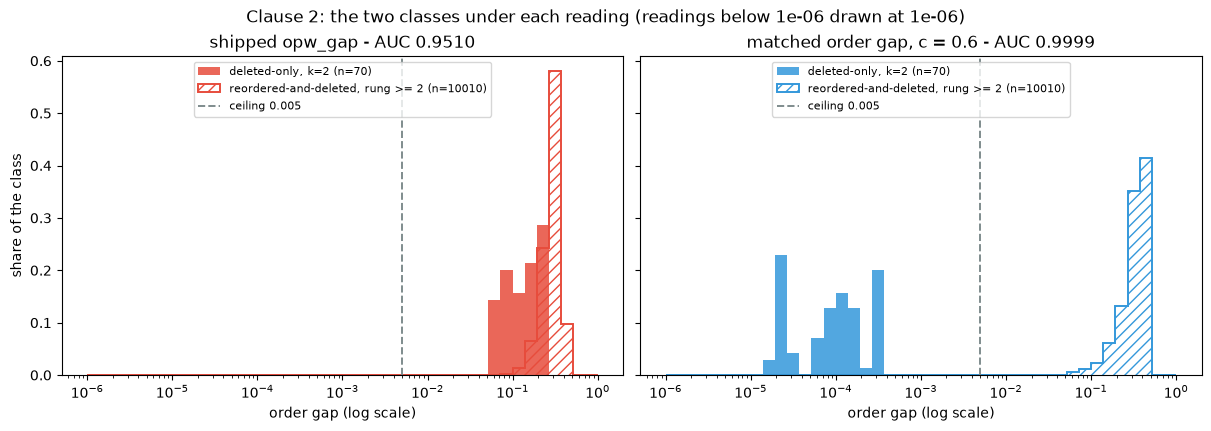

In [17]:
bins = np.logspace(-6, 0, 43)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True, sharey=True)
for ax, method, colour, title in (
    (axes[0], "shipped", COL_SHIPPED, f"shipped opw_gap - AUC {AUC_SHIPPED:.4f}"),
    (axes[1], REG, COL_MATCHED, f"matched order gap, c = {C_REGISTERED} - AUC {AUC_MATCHED:.4f}"),
):
    neg = np.maximum(neg_df[method].to_numpy(), bins[0])
    pos = np.maximum(sep_df[method].to_numpy(), bins[0])
    ax.hist(neg, bins=bins, weights=np.full(len(neg), 1 / len(neg)), color=colour, alpha=0.85, label=f"deleted-only, k={K_SEPARATION} (n={len(neg)})")
    ax.hist(pos, bins=bins, weights=np.full(len(pos), 1 / len(pos)), histtype="step", hatch="///", color=colour, lw=1.4,
            label=f"reordered-and-deleted, rung >= {RUNG_MIN} (n={len(pos)})")
    ax.axvline(GAP_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"ceiling {GAP_BAR}")
    ax.set_xscale("log")
    ax.set_xlabel("order gap (log scale)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper center")
axes[0].set_ylabel("share of the class")
fig.suptitle("Clause 2: the two classes under each reading (readings below 1e-06 drawn at 1e-06)")
plt.show()

## Clause 3 - bit-identity on fully matched equal-length pairs

Every pair the structure fixture defines is enumerated: the cross-summary pairs of both articles, the tier-contrast
pairs, the paraphrase pairs, the summary-against-source pair, every reorder-pool entry as `(base, base[perm])`, and
one identity pair per base for the section-swap family (a section swap moves a block label only, so its statement
sequence is the base itself). A pair is eligible when both documents have the same length and the matching at
`c = 0.6` pairs every statement. On the eligible pairs the matched gap must equal shipped `opw_gap` under
`np.array_equal`.

In [18]:
fixture_pairs = []             # (family, label_a, label_b, A, B)
for article, listed in PAIRS["cross_summary"].items():
    fixture_pairs += [(f"cross_summary/{article}", a, b, EMB[a], EMB[b]) for a, b in listed]
fixture_pairs += [("tier_contrast", p["a"], p["b"], EMB[p["a"]], EMB[p["b"]]) for p in PAIRS["tier_contrast"]]
fixture_pairs += [(f"paraphrase/{p['kind']}", p["a"], p["b"], EMB[p["a"]], EMB[p["b"]]) for p in PAIRS["paraphrase"]]
summary_label, source_label = PAIRS["section_summary_source"]
fixture_pairs.append(("section_summary_source", summary_label, source_label, EMB[summary_label], EMB[source_label]))
fixture_pairs += [("section_swap (identity sequence)", base, base, EMB[base], EMB[base]) for base in PAIRS["section_swap"]]
for base in BASES:
    fixture_pairs += [("reorder_pool", base, f"{base}[k={e['k']},seed={e['seed']}]", EMB[base], EMB[base][e["perm"]]) for e in REORDER[base]]

print(f"{len(fixture_pairs)} fixture pairs enumerated over {len(set(pair[0] for pair in fixture_pairs))} families")

1913 fixture pairs enumerated over 8 families


In [19]:
identity_rows = []
for family, label_a, label_b, A, B in tqdm(fixture_pairs, desc="fixture pairs", mininterval=15.0, file=sys.stdout):
    row = {"family": family, "a": label_a, "b": label_b, "n_a": len(A), "n_b": len(B), "shipped": opw_gap(A, B)}
    for c in CUTOFFS:
        row[f"matched_{tag(c)}"], row[f"n_matched_{tag(c)}"] = matched_opw_gap(A, B, c)
        row[f"eligible_{tag(c)}"] = bool(len(A) == len(B) == row[f"n_matched_{tag(c)}"])
    identity_rows.append(row)
pair_df = pl.DataFrame(identity_rows)

fixture pairs:   0%|          | 0/1913 [00:00<?, ?it/s]

fixture pairs: 100%|██████████| 1913/1913 [00:03<00:00, 501.94it/s]

In [20]:
ELIG = f"eligible_{tag(C_REGISTERED)}"
eligible_df = pair_df.filter(pl.col(ELIG))
N_FIXTURE_PAIRS, N_EQUAL_LENGTH, N_ELIGIBLE = pair_df.height, pair_df.filter(pl.col("n_a") == pl.col("n_b")).height, eligible_df.height
BIT_IDENTICAL = bool(np.array_equal(eligible_df[REG].to_numpy(), eligible_df["shipped"].to_numpy()))
N_IDENTICAL = int((eligible_df[REG].to_numpy() == eligible_df["shipped"].to_numpy()).sum())
MAX_ABS_DIFF = float(np.abs(eligible_df[REG].to_numpy() - eligible_df["shipped"].to_numpy()).max())
CLAUSE3_MET = bool(BIT_IDENTICAL and N_ELIGIBLE > 0)

# the same reading without the full-match branch of matched_opw_gap: both documents always indexed
eligible_pairs = [pair for pair, ok in zip(fixture_pairs, pair_df[ELIG].to_list()) if ok]
indexed = np.array([opw_gap(A[np.sort(rows)], B[np.sort(cols)])
                    for _, _, _, A, B in eligible_pairs for rows, cols in [match_statements(A, B, C_REGISTERED)]])
indexed_differs = indexed != eligible_df["shipped"].to_numpy()
N_INDEXED_IDENTICAL = int((~indexed_differs).sum())
INDEXED_DIFF_FAMILIES = sorted(set(eligible_df.filter(pl.Series(indexed_differs))["family"].to_list()))
INDEXED_MAX_ABS_DIFF = float(np.abs(indexed - eligible_df["shipped"].to_numpy()).max())

by_family = (
    pair_df.group_by("family")
    .agg(pl.len().alias("pairs"), (pl.col("n_a") == pl.col("n_b")).sum().alias("equal_length"), pl.col(ELIG).sum().alias("eligible"),
         (pl.col(ELIG) & (pl.col(REG) == pl.col("shipped"))).sum().alias("identical"))
    .sort("family")
)
t = Table(title=f"Clause 3 - matched gap at c = {C_REGISTERED} against shipped opw_gap, by fixture family", header_style="bold medium_purple")
for column in ("family", "pairs", "equal length", "fully matched (eligible)", "exactly equal"):
    t.add_column(column, justify="left" if column == "family" else "right")
for row in by_family.iter_rows(named=True):
    t.add_row(row["family"], str(row["pairs"]), str(row["equal_length"]), str(row["eligible"]), f"{row['identical']}/{row['eligible']}")
t.add_row("all", str(N_FIXTURE_PAIRS), str(N_EQUAL_LENGTH), str(N_ELIGIBLE), f"{N_IDENTICAL}/{N_ELIGIBLE}", style="bold")
c3_colour = "dark_sea_green" if CLAUSE3_MET else "indian_red"
console.print(Group(t, Panel(
    f"[bold {c3_colour}]clause 3 {'MET' if CLAUSE3_MET else 'NOT MET'}[/bold {c3_colour}]: np.array_equal = {BIT_IDENTICAL} on {N_ELIGIBLE} eligible pairs"
    f" ({N_IDENTICAL} exactly equal, largest |difference| {MAX_ABS_DIFF!r})\n"
    f"without the full-match branch (both documents always indexed): {N_INDEXED_IDENTICAL}/{N_ELIGIBLE} exactly equal,"
    f" largest |difference| {INDEXED_MAX_ABS_DIFF:.3e}, differing families: {INDEXED_DIFF_FAMILIES or 'none'}",
    border_style=c3_colour, expand=False)))

             Clause 3 - matched gap at c = 0.6 against shipped opw_gap, by fixture family             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ family                           ┃ pairs ┃ equal length ┃ fully matched (eligible) ┃ exactly equal ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cross_summary/ibm                │    55 │            4 │                        4 │           4/4 │
│ cross_summary/wergeland          │     3 │            0 │                        0 │           0/0 │
│ paraphrase/ab_regen              │     4 │            2 │                        2 │           2/2 │
│ paraphrase/backtranslation       │    10 │           10 │                       10 │         10/10 │
│ reorder_pool                     │  1820 │         1820 │                     1820 │     1820/1820 │
│ section_summary_source           │     1 │            0 │                        0 │           0/0 │
│ section_swap (identity sequence) │    10 │           10 │                       10 │         10/10 │
│ tier_contrast                    │    10 │            1 │                        1 │           1/1 │
│ all                              │  1913 │         1847 │                     1847 │     1847/1847 │
└──────────────────────────────────┴───────┴──────────────┴──────────────────────────┴───────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clause 3 MET: np.array_equal = True on 1847 eligible pairs (1847 exactly equal, largest |difference| 0.0)       │
│ without the full-match branch (both documents always indexed): 1837/1847 exactly equal, largest |difference|    │
│ 2.108e-06, differing families: ['section_swap (identity sequence)']                                             │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

The scatter places every eligible pair by its shipped reading (x) and its matched reading (y). Exact equality puts
every marker on the dashed identity line; the marker shape names the fixture family.

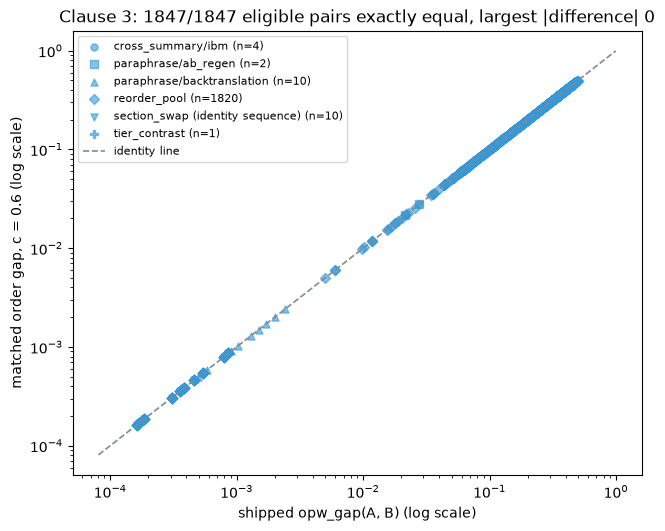

In [21]:
fig, ax = plt.subplots(figsize=(6.4, 5.2), constrained_layout=True)
markers = dict(zip(sorted(eligible_df["family"].unique().to_list()), ("o", "s", "^", "D", "v", "P", "X", "*")))
for family, marker in markers.items():
    sub = eligible_df.filter(pl.col("family") == family)
    ax.scatter(sub["shipped"].to_numpy(), sub[REG].to_numpy(), s=26, alpha=0.6, color=COL_MATCHED, marker=marker,
               label=f"{family} (n={sub.height})")
span = [float(eligible_df["shipped"].min()) / 2, float(eligible_df["shipped"].max()) * 2]
ax.plot(span, span, color=COL_REFERENCE, ls="--", lw=1.2, label="identity line")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("shipped opw_gap(A, B) (log scale)")
ax.set_ylabel(f"matched order gap, c = {C_REGISTERED} (log scale)")
ax.set_title(f"Clause 3: {N_IDENTICAL}/{N_ELIGIBLE} eligible pairs exactly equal, largest |difference| {MAX_ABS_DIFF:g}")
ax.legend(fontsize=8, loc="upper left")
plt.show()

The fixture pairs of unequal length are outside clause 3 and outside the registered bar. No ground truth states what
their order gap should read, so the table below is a reading and not a test: it shows in which direction and by how
much the matched gap moves pairs that are not synthetic deletions.

In [22]:
N_MATCHED = f"n_matched_{tag(C_REGISTERED)}"
unequal_df = pair_df.filter(pl.col("n_a") != pl.col("n_b"))


def unequal_summary(frame: pl.DataFrame) -> dict:
    """Shipped against matched order gap over unequal-length pairs; pairs with no matched statement are counted apart."""
    shipped, matched = frame["shipped"].to_numpy(), frame[REG].to_numpy()
    scored = ~np.isnan(matched)
    shorter = np.minimum(frame["n_a"].to_numpy(), frame["n_b"].to_numpy())
    return {
        "pairs": frame.height, "no_matched_pair": int((~scored).sum()),
        "shipped_median": float(np.median(shipped)), "matched_median": float(np.median(matched[scored])),
        "matched_below_shipped": int((matched[scored] < shipped[scored]).sum()),
        "matched_above_shipped": int((matched[scored] > shipped[scored]).sum()),
        "shipped_within_bar": int((shipped <= GAP_BAR).sum()), "matched_within_bar": int((matched[scored] <= GAP_BAR).sum()),
        "matched_max": float(matched[scored].max()),
        "shorter_fully_matched": int((frame[N_MATCHED].to_numpy() == shorter).sum()),
    }


UNEQUAL = {family: unequal_summary(unequal_df.filter(pl.col("family") == family)) for family in sorted(unequal_df["family"].unique().to_list())}
UNEQUAL["all"] = unequal_summary(unequal_df)

t = Table(title=f"Outside the bar - the {unequal_df.height} fixture pairs of unequal length, shipped against matched (c = {C_REGISTERED})",
          header_style="bold medium_purple")
t.add_column("family", no_wrap=True)
for column in ("pairs", "shipped median", "matched median", "matched below / above shipped", f"<= {GAP_BAR}: shipped / matched",
               "matched max", "shorter side fully matched"):
    t.add_column(column, justify="right")
for family, row in UNEQUAL.items():
    t.add_row(family, str(row["pairs"]), f"{row['shipped_median']:.4f}", f"{row['matched_median']:.4f}",
              f"{row['matched_below_shipped']} / {row['matched_above_shipped']}", f"{row['shipped_within_bar']} / {row['matched_within_bar']}",
              f"{row['matched_max']:.4f}", f"{row['shorter_fully_matched']}/{row['pairs']}", style="bold" if family == "all" else None)
console.print(Group(t,
    f"[dim]'shorter side fully matched' = pairs in which every statement of the shorter document is matched below c = {C_REGISTERED};"
    f" pairs with no matched statement: {UNEQUAL['all']['no_matched_pair']}; no ground truth exists for these pairs[/dim]"))

            Outside the bar - the 66 fixture pairs of unequal length, shipped against matched (c = 0.6)            
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃                         ┃       ┃            ┃            ┃     matched ┃            ┃             ┃            ┃
┃                         ┃       ┃            ┃            ┃     below / ┃  <= 0.005: ┃             ┃    shorter ┃
┃                         ┃       ┃    shipped ┃    matched ┃       above ┃  shipped / ┃             ┃ side fully ┃
┃ family                  ┃ pairs ┃     median ┃     median ┃     shipped ┃    matched ┃ matched max ┃    matched ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ cross_summary/ibm       │    51 │     0.0414 │     0.0186 │     35 / 16 │     0 / 19 │      0.1621 │      45/51 │
│ cross_summary/wergeland │     3 │     0.0317 │     0.0377 │       1 / 2 │      0 / 0 │      0.0452 │        3/3 │
│ paraphrase/ab_regen     │     2 │     0.0746 │     0.0811 │       1 / 1 │      0 / 1 │      0.1621 │        2/2 │
│ section_summary_source  │     1 │     0.0687 │     0.0867 │       0 / 1 │      0 / 0 │      0.0867 │        1/1 │
│ tier_contrast           │     9 │     0.0563 │     0.0598 │       5 / 4 │      0 / 2 │      0.1621 │        8/9 │
│ all                     │    66 │     0.0438 │     0.0200 │     42 / 24 │     0 / 22 │      0.1621 │      59/66 │
└─────────────────────────┴───────┴────────────┴────────────┴─────────────┴────────────┴─────────────┴────────────┘
'shorter side fully matched' = pairs in which every statement of the shorter document is matched below c = 0.6; 
pairs with no matched statement: 0; no ground truth exists for these pairs

## Prediction - retention of the reorder rung

The prediction's second half says reordered-and-deleted cases stay near their reorder rung. Per E11 rung, the table
puts three medians side by side: the shipped order gap of the reorder alone, the shipped order gap after the
additional `k=2` deletion, and the matched order gap after the deletion. Retention is read under the two rules of
the configuration cell, both written by the executor: the executor rule (the matched median lies strictly between
the reorder-only medians of the two adjacent rungs) and the nearest-median rule (the reorder-only median nearest to
the matched median is the rung's own). The executor rule is also applied to the shipped medians, as a control that
it can fail.

In [23]:
reorder_median = {r: float(pool_df.filter(pl.col("rung") == r)["reorder_only"].median()) for r in range(1, N_RUNGS + 1)}


def retained_under_executor_rule(median: float, r: int) -> bool:
    """True when ``median`` lies strictly between the reorder-only medians of the rungs adjacent to rung ``r``."""
    lower = reorder_median[r - 1] if r > 1 else -np.inf
    upper = reorder_median[r + 1] if r < N_RUNGS else np.inf
    return bool(lower < median < upper)


rung_rows = []
for r in range(1, N_RUNGS + 1):
    sub = pos_df.filter(pl.col("rung") == r)
    matched_median, shipped_median = float(sub[REG].median()), float(sub["shipped"].median())
    rung_rows.append({
        "rung": r, "perms": pool_df.filter(pl.col("rung") == r).height, "cases": sub.height,
        "reorder_only": reorder_median[r], "shipped_after_deletion": shipped_median,
        "matched_after_deletion": matched_median, "ratio": matched_median / reorder_median[r],
        "nearest_rung": min(reorder_median, key=lambda q: abs(reorder_median[q] - matched_median)),
        "retained": retained_under_executor_rule(matched_median, r),
        "shipped_retained": retained_under_executor_rule(shipped_median, r),
        "same_rung_after": float((sub["disp_after"].map_elements(rung_of, return_dtype=pl.Int64) == r).mean()),
        "q25": float(sub[REG].quantile(0.25)), "q75": float(sub[REG].quantile(0.75)),
        "ro_q25": float(pool_df.filter(pl.col("rung") == r)["reorder_only"].quantile(0.25)),
        "ro_q75": float(pool_df.filter(pl.col("rung") == r)["reorder_only"].quantile(0.75)),
        "sh_q25": float(sub["shipped"].quantile(0.25)), "sh_q75": float(sub["shipped"].quantile(0.75)),
    })
rung_df = pl.DataFrame(rung_rows)
in_bar_rungs = rung_df.filter(pl.col("rung") >= RUNG_MIN)
RUNGS_TESTED = N_RUNGS - RUNG_MIN + 1
RUNGS_RETAINED = int(in_bar_rungs["retained"].sum())                                   # executor rule
RUNGS_NEAREST_OWN = int((in_bar_rungs["nearest_rung"] == in_bar_rungs["rung"]).sum())  # nearest-median rule
RUNGS_RETAINED_SHIPPED = int(in_bar_rungs["shipped_retained"].sum())                   # executor rule on the shipped medians
RUNG_HELD_EXECUTOR_RULE = bool(RUNGS_RETAINED == RUNGS_TESTED)
RUNG_HELD_NEAREST_MEDIAN = bool(RUNGS_NEAREST_OWN == RUNGS_TESTED)
SPEARMAN_REORDER = float(pl.DataFrame({"a": sep_df[REG], "b": sep_df["reorder_only"]}).select(pl.corr("a", "b", method="spearman")).item())

t = Table(title=f"Median order gap per E11 rung - reorder alone, then with k={K_SEPARATION} statements deleted", header_style="bold medium_purple")
for column in ("rung", "perms", "cases", "reorder only", "+ deletion, shipped", "+ deletion, matched", "matched / reorder only",
               "nearest rung", "executor rule", "same rung after"):
    t.add_column(column, justify="right")
for row in rung_df.iter_rows(named=True):
    t.add_row(str(row["rung"]), str(row["perms"]), str(row["cases"]), f"{row['reorder_only']:.5f}", f"{row['shipped_after_deletion']:.5f}",
              f"{row['matched_after_deletion']:.5f}", f"{row['ratio']:.3f}", str(row["nearest_rung"]),
              ("yes" if row["retained"] else "no") if row["rung"] >= RUNG_MIN else "-", f"{row['same_rung_after']:.1%}")
rp_colour = "dark_sea_green" if RUNG_HELD_EXECUTOR_RULE and RUNG_HELD_NEAREST_MEDIAN else "dark_goldenrod"
console.print(Group(t, Panel(
    f"[bold {rp_colour}]rungs retained: {RUNGS_RETAINED}/{RUNGS_TESTED} under the executor rule, {RUNGS_NEAREST_OWN}/{RUNGS_TESTED} under the"
    f" nearest-median rule[/bold {rp_colour}] (rungs {RUNG_MIN} to {N_RUNGS}; rung 1 is outside the registered positive class)\n"
    f"executor rule: the matched median lies strictly between the reorder-only medians of the adjacent rungs | nearest-median rule: the"
    f" reorder-only median nearest to the matched median is the rung's own\n"
    f"control - the executor rule applied to the shipped medians after the deletion retains {RUNGS_RETAINED_SHIPPED}/{RUNGS_TESTED} rungs\n"
    f"columns: medians of the shipped order gap of the reorder alone, then of the shipped and of the matched (c = {C_REGISTERED}) order gap"
    f" after the k={K_SEPARATION} deletion; 'same rung after' = share of cases whose surviving statements still sit in the rung of the permutation\n"
    f"Spearman(matched gap after deletion, reorder-only gap of the same permutation) over the {N_POS} positives: {SPEARMAN_REORDER:.4f}",
    border_style=rp_colour, expand=False)))

                  Median order gap per E11 rung - reorder alone, then with k=2 statements deleted                  
┏━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃      ┃       ┃       ┃            ┃          + ┃          + ┃  matched / ┃            ┃            ┃            ┃
┃      ┃       ┃       ┃    reorder ┃  deletion, ┃  deletion, ┃    reorder ┃    nearest ┃   executor ┃  same rung ┃
┃ rung ┃ perms ┃ cases ┃       only ┃    shipped ┃    matched ┃       only ┃       rung ┃       rule ┃      after ┃
┡━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│    1 │   181 │  1267 │    0.07549 │    0.16435 │    0.08980 │      1.190 │          1 │          - │      85.3% │
│    2 │   272 │  1904 │    0.15524 │    0.21709 │    0.20454 │      1.318 │          2 │        yes │      75.1% │
│    3 │   313 │  2191 │    0.25920 │    0.26709 │    0.30459 │      1.175 │          4 │        yes │      68.1% │
│    4 │   415 │  2905 │    0.34850 │    0.31292 │    0.37089 │      1.064 │          4 │        yes │      68.9% │
│    5 │   287 │  2009 │    0.40234 │    0.34148 │    0.40532 │      1.007 │          5 │        yes │      66.2% │
│    6 │   143 │  1001 │    0.42441 │    0.35830 │    0.42541 │      1.002 │          6 │        yes │      85.6% │
└──────┴───────┴───────┴────────────┴────────────┴────────────┴────────────┴────────────┴────────────┴────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ rungs retained: 5/5 under the executor rule, 4/5 under the nearest-median rule (rungs 2 to 6; rung 1 is outside │
│ the registered positive class)                                                                                  │
│ executor rule: the matched median lies strictly between the reorder-only medians of the adjacent rungs |        │
│ nearest-median rule: the reorder-only median nearest to the matched median is the rung's own                    │
│ control - the executor rule applied to the shipped medians after the deletion retains 3/5 rungs                 │
│ columns: medians of the shipped order gap of the reorder alone, then of the shipped and of the matched (c =     │
│ 0.6) order gap after the k=2 deletion; 'same rung after' = share of cases whose surviving statements still sit  │
│ in the rung of the permutation                                                                                  │
│ Spearman(matched gap after deletion, reorder-only gap of the same permutation) over the 10010 positives: 0.8058 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

The figure draws the three medians per rung with their interquartile ranges. The reading to check is whether the
matched series (squares) follows the reorder-only series (triangles) or the shipped-after-deletion series (circles).

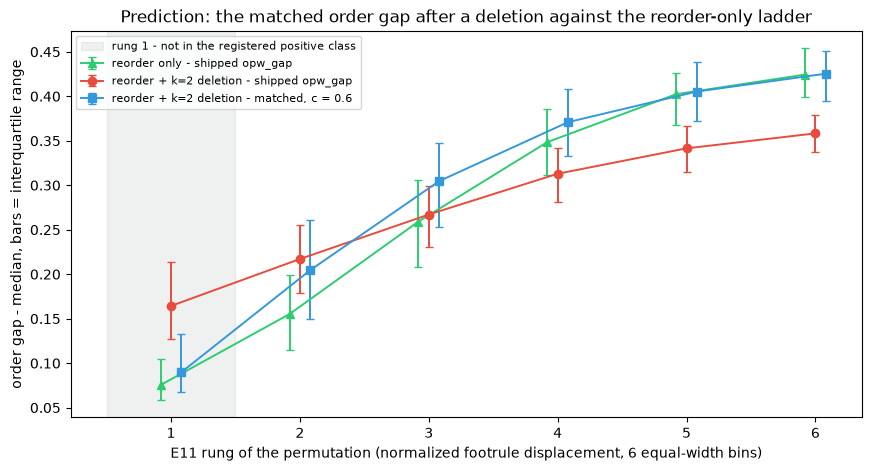

In [24]:
fig, ax = plt.subplots(figsize=(8.6, 4.6), constrained_layout=True)
rungs = rung_df["rung"].to_numpy()
for offset, median, low, high, colour, marker, label in (
    (-0.08, "reorder_only", "ro_q25", "ro_q75", COL_REORDER, "^", "reorder only - shipped opw_gap"),
    (0.0, "shipped_after_deletion", "sh_q25", "sh_q75", COL_SHIPPED, "o", f"reorder + k={K_SEPARATION} deletion - shipped opw_gap"),
    (+0.08, "matched_after_deletion", "q25", "q75", COL_MATCHED, "s", f"reorder + k={K_SEPARATION} deletion - matched, c = {C_REGISTERED}"),
):
    m = rung_df[median].to_numpy()
    ax.errorbar(rungs + offset, m, yerr=[m - rung_df[low].to_numpy(), rung_df[high].to_numpy() - m], color=colour,
                marker=marker, ms=6, lw=1.4, capsize=3, label=label)
ax.axvspan(0.5, RUNG_MIN - 0.5, color=COL_REFERENCE, alpha=0.12, label="rung 1 - not in the registered positive class")
ax.set_xticks(rungs)
ax.set_xlabel("E11 rung of the permutation (normalized footrule displacement, 6 equal-width bins)")
ax.set_ylabel("order gap - median, bars = interquartile range")
ax.set_title("Prediction: the matched order gap after a deletion against the reorder-only ladder")
ax.legend(fontsize=8, loc="upper left")
plt.show()

## Cutoff sensitivity

The three clause readings at the sensitivity cutoffs `0.35` and `0.45` beside the registered `0.6`. The record
attaches no bar to the sensitivity arms. The last two columns state whether the per-case readings at a cutoff are
exactly the readings at `0.6`.

In [25]:
sens_rows = []
for c in CUTOFFS:
    column, eligible_column = f"matched_{tag(c)}", f"eligible_{tag(c)}"
    eligible = pair_df.filter(pl.col(eligible_column))
    sens_rows.append({
        "c": c,
        "deletion_within_bar": int((del_df[column] <= GAP_BAR).sum()),
        "deletion_share": float((del_df[column] <= GAP_BAR).mean()),
        "deletion_median_k2": float(del_df.filter(pl.col("k") == 2)[column].median()),
        "auc": auc(neg_df[column].to_numpy(), sep_df[column].to_numpy()),
        "eligible_pairs": eligible.height,
        "bit_identical": bool(np.array_equal(eligible[column].to_numpy(), eligible["shipped"].to_numpy())),
        "deletion_equal_to_registered": bool(np.array_equal(del_df[column].to_numpy(), del_df[REG].to_numpy())),
        "positives_equal_to_registered": bool(np.array_equal(sep_df[column].to_numpy(), sep_df[REG].to_numpy())),
    })
sens_df = pl.DataFrame(sens_rows)
SENSITIVITY_INERT = bool(sens_df["deletion_equal_to_registered"].all() and sens_df["positives_equal_to_registered"].all())

t = Table(title="Cutoff sensitivity - the clause readings per cutoff (no bar at 0.35 and 0.45)", header_style="bold medium_purple")
for column in ("c", f"<= {GAP_BAR}", "median k=2", "AUC", "eligible", "identical", "deletions = 0.6", "positives = 0.6"):
    t.add_column(column, justify="right")
for row in sens_df.iter_rows(named=True):
    t.add_row(f"{row['c']}" + (" (registered)" if row["c"] == C_REGISTERED else ""), f"{row['deletion_within_bar']}/{del_df.height}",
              f"{row['deletion_median_k2']:.3e}", f"{row['auc']:.6f}", str(row["eligible_pairs"]), str(row["bit_identical"]),
              str(row["deletion_equal_to_registered"]), str(row["positives_equal_to_registered"]))
console.print(Group(t,
    f"[bold]per-case readings exactly equal at all three cutoffs on the registered deletion and positive sets: {SENSITIVITY_INERT}[/bold]\n"
    f"[dim]columns: deletion cases at or below the ceiling, matched median at k=2, clause 2 AUC, eligible pairs of clause 3 and their"
    f" np.array_equal, np.array_equal of the per-case readings against the readings at c = {C_REGISTERED}[/dim]"))

                  Cutoff sensitivity - the clause readings per cutoff (no bar at 0.35 and 0.45)                   
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃                c ┃ <= 0.005 ┃ median k=2 ┃      AUC ┃ eligible ┃ identical ┃ deletions = 0.6 ┃ positives = 0.6 ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│             0.35 │  280/280 │  9.671e-05 │ 0.999903 │     1840 │      True │            True │            True │
│             0.45 │  280/280 │  9.671e-05 │ 0.999903 │     1845 │      True │            True │            True │
│ 0.6 (registered) │  280/280 │  9.671e-05 │ 0.999903 │     1847 │      True │            True │            True │
└──────────────────┴──────────┴────────────┴──────────┴──────────┴───────────┴─────────────────┴─────────────────┘
per-case readings exactly equal at all three cutoffs on the registered deletion and positive sets: True
columns: deletion cases at or below the ceiling, matched median at k=2, clause 2 AUC, eligible pairs of clause 3 
and their np.array_equal, np.array_equal of the per-case readings against the readings at c = 0.6

## Second pass - the cutoff on reworded survivors (outside the registered bar)

The sensitivity table raises a question: the three cutoffs give exactly the same reading on every registered case.
The registered deletion and reorder cases keep the surviving statements byte-identical, so every true pair has a
ground cost near `0` and no cutoff between `0.35` and `0.6` can change the matching. This pass repeats the 280
deletion plans on the back-translation paraphrase of each base (`<base>~bt`, a per-statement reword of equal
length, the E11 content-invariance control). The pair is `(A, P minus k statements)`, where statement `i` of `P`
rewords statement `i` of `A`: order is still preserved and the survivors are no longer identical, so every true
pair has a nonzero ground cost that a cutoff could reject. The record registers no bar for this arm and it does
not enter the verdict.

The first cell verifies the statement alignment that serves as ground truth and reads the cost of the true pairs.

In [26]:
para_rows, true_costs = [], []
for base in BASES:
    A, P = EMB[base], EMB[f"{base}~bt"]
    cost = cost_matrix(A, P)
    true_costs.append(np.diag(cost))
    para_rows.append({
        "base": base, "n": len(A), "aligned": int((cost.argmin(1) == np.arange(len(A))).sum()),
        "true_cost_median": float(np.median(np.diag(cost))), "true_cost_max": float(np.diag(cost).max()),
        "other_cost_min": float(cost[~np.eye(len(A), dtype=bool)].min()), "paraphrase_gap": opw_gap(A, P),
    })
para_df = pl.DataFrame(para_rows)
TRUE_COSTS = np.concatenate(true_costs)
PARA_ALIGNED, PARA_STATEMENTS = int(para_df["aligned"].sum()), int(para_df["n"].sum())
PARA_GAP_MAX = float(para_df["paraphrase_gap"].max())
TRUE_AT_OR_ABOVE = {c: int((TRUE_COSTS >= c).sum()) for c in CUTOFFS}

t = Table(title="Back-translation paraphrase against its base - alignment and ground cost of the true pairs", header_style="bold medium_purple")
for column in ("base", "n", "row minimum on the diagonal", "true-pair cost median", "true-pair cost max", "smallest cost of another pair", "opw_gap(A, P)"):
    t.add_column(column, justify="left" if column == "base" else "right")
for row in para_df.iter_rows(named=True):
    t.add_row(row["base"], str(row["n"]), f"{row['aligned']}/{row['n']}", f"{row['true_cost_median']:.4f}", f"{row['true_cost_max']:.4f}",
              f"{row['other_cost_min']:.4f}", f"{row['paraphrase_gap']:.6f}")
console.print(Group(t,
    f"[bold]statements whose reword is their cheapest partner: {PARA_ALIGNED}/{PARA_STATEMENTS}[/bold]\n"
    f"ground cost of the {PARA_STATEMENTS} true pairs: median {float(np.median(TRUE_COSTS)):.6f}, max {float(TRUE_COSTS.max()):.6f}\n"
    f"true pairs at or above each cutoff: " + ", ".join(f"c = {c}: {TRUE_AT_OR_ABOVE[c]}/{PARA_STATEMENTS}" for c in CUTOFFS) + "\n"
    f"equal-length paraphrase order gap opw_gap(A, P): median {float(para_df['paraphrase_gap'].median()):.6f}, max {PARA_GAP_MAX:.6f}"))

            Back-translation paraphrase against its base - alignment and ground cost of the true pairs             
┏━━━━━━━━┳━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃        ┃    ┃ row minimum on the ┃     true-pair cost ┃                    ┃   smallest cost of ┃               ┃
┃ base   ┃  n ┃           diagonal ┃             median ┃ true-pair cost max ┃       another pair ┃ opw_gap(A, P) ┃
┡━━━━━━━━╇━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gold   │ 11 │              11/11 │             0.1387 │             0.2886 │             0.3004 │      0.000492 │
│ gold-2 │ 13 │              13/13 │             0.1409 │             0.2621 │             0.2897 │      0.001489 │
│ v1     │ 12 │              12/12 │             0.1533 │             0.2136 │             0.3007 │      0.000901 │
│ v2     │ 12 │              12/12 │             0.1394 │             0.3069 │             0.2672 │      0.001024 │
│ opus   │ 13 │              13/13 │             0.1772 │             0.2978 │             0.2990 │      0.001718 │
│ sonnet │ 11 │              11/11 │             0.1558 │             0.2352 │             0.3018 │      0.000588 │
│ haiku  │ 14 │              14/14 │             0.1582 │             0.3229 │             0.3198 │      0.002414 │
│ werg-a │ 11 │              11/11 │             0.1447 │             0.2220 │             0.3106 │      0.000469 │
│ werg-b │ 13 │              13/13 │             0.1702 │             0.2562 │             0.3451 │      0.001304 │
│ werg-c │ 14 │              14/14 │             0.1382 │             0.2186 │             0.3108 │      0.001997 │
└────────┴────┴────────────────────┴────────────────────┴────────────────────┴────────────────────┴───────────────┘
statements whose reword is their cheapest partner: 124/124
ground cost of the 124 true pairs: median 0.154685, max 0.322901
true pairs at or above each cutoff: c = 0.35: 0/124, c = 0.45: 0/124, c = 0.6: 0/124
equal-length paraphrase order gap opw_gap(A, P): median 0.001164, max 0.002414

In [27]:
rw_rows = []
for case in CASES:
    A = EMB[case["base"]]
    B = EMB[f"{case['base']}~bt"][case["keep"]]
    row = {"base": case["base"], "k": case["k"], "n_b": len(B), **score_case(A, B)}
    for c in CUTOFFS:
        rows, cols = match_statements(A, B, c)
        row[f"true_pairs_only_{tag(c)}"] = bool(np.array_equal(rows, np.asarray(case["keep"])[cols]))
    rw_rows.append(row)
rw_df = pl.DataFrame(rw_rows)


def reading_summary(values: pl.Series) -> dict:
    """Ceiling count, median, p95 and max of one reading over the reworded deletion cases; ``nan`` rows are excluded."""
    finite = values.drop_nans()
    return {"within_bar": int((finite <= GAP_BAR).sum()), "no_matched_pair": values.len() - finite.len(),
            "median": float(finite.median()), "p95": float(finite.quantile(0.95)), "max": float(finite.max())}


RW = {"shipped": reading_summary(rw_df["shipped"])}
for c in CUTOFFS:
    RW[c] = reading_summary(rw_df[f"matched_{tag(c)}"]) | {
        "matched_share_of_survivors": float((rw_df[f"n_matched_{tag(c)}"] / rw_df["n_b"]).mean()),
        "cases_with_every_survivor_matched": int((rw_df[f"n_matched_{tag(c)}"] == rw_df["n_b"]).sum()),
        "cases_with_true_pairs_only": int(rw_df[f"true_pairs_only_{tag(c)}"].sum()),
    }

t = Table(title="Second pass - the 280 deletion plans on reworded survivors, pair (A, P minus k statements)", header_style="bold medium_purple")
for column in ("reading", f"<= {GAP_BAR}", "median", "p95", "max", "survivors matched", "every survivor matched", "true pairs only"):
    t.add_column(column, justify="left" if column == "reading" else "right")
t.add_row("shipped opw_gap", f"{RW['shipped']['within_bar']}/{rw_df.height}", f"{RW['shipped']['median']:.6f}", f"{RW['shipped']['p95']:.6f}",
          f"{RW['shipped']['max']:.6f}", "-", "-", "-")
for c in CUTOFFS:
    t.add_row(f"matched, c = {c}" + (" (registered)" if c == C_REGISTERED else ""), f"{RW[c]['within_bar']}/{rw_df.height}", f"{RW[c]['median']:.6f}",
              f"{RW[c]['p95']:.6f}", f"{RW[c]['max']:.6f}", f"{RW[c]['matched_share_of_survivors']:.1%}",
              f"{RW[c]['cases_with_every_survivor_matched']}/{rw_df.height}", f"{RW[c]['cases_with_true_pairs_only']}/{rw_df.height}")
console.print(Group(t,
    "[dim]'survivors matched' = mean share of the statements of the shortened paraphrase that enter the matched sub-sequence;"
    " 'true pairs only' = cases in which every matched pair joins a statement with its own reword;"
    " cases with no matched pair: " + ", ".join(f"c = {c}: {RW[c]['no_matched_pair']}" for c in CUTOFFS) + "[/dim]"))

            Second pass - the 280 deletion plans on reworded survivors, pair (A, P minus k statements)             
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃                 ┃          ┃          ┃          ┃          ┃      survivors ┃  every survivor ┃     true pairs ┃
┃ reading         ┃ <= 0.005 ┃   median ┃      p95 ┃      max ┃        matched ┃         matched ┃           only ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ shipped opw_gap │    0/280 │ 0.076387 │ 0.167415 │ 0.206270 │              - │               - │              - │
│ matched, c =    │  280/280 │ 0.000218 │ 0.001150 │ 0.001752 │         100.0% │         280/280 │        280/280 │
│ 0.35            │          │          │          │          │                │                 │                │
│ matched, c =    │  280/280 │ 0.000218 │ 0.001150 │ 0.001752 │         100.0% │         280/280 │        280/280 │
│ 0.45            │          │          │          │          │                │                 │                │
│ matched, c =    │  280/280 │ 0.000218 │ 0.001150 │ 0.001752 │         100.0% │         280/280 │        280/280 │
│ 0.6             │          │          │          │          │                │                 │                │
│ (registered)    │          │          │          │          │                │                 │                │
└─────────────────┴──────────┴──────────┴──────────┴──────────┴────────────────┴─────────────────┴────────────────┘
'survivors matched' = mean share of the statements of the shortened paraphrase that enter the matched sub-sequence;
'true pairs only' = cases in which every matched pair joins a statement with its own reword; cases with no matched 
pair: c = 0.35: 0, c = 0.45: 0, c = 0.6: 0

The figure shows the 280 reworded deletion cases under the shipped order gap and under the matched order gap at each
cutoff. The reading to check is the position of each column relative to the ceiling (dashed) and to the largest
equal-length paraphrase order gap (dotted), and whether the three cutoff columns differ from each other.

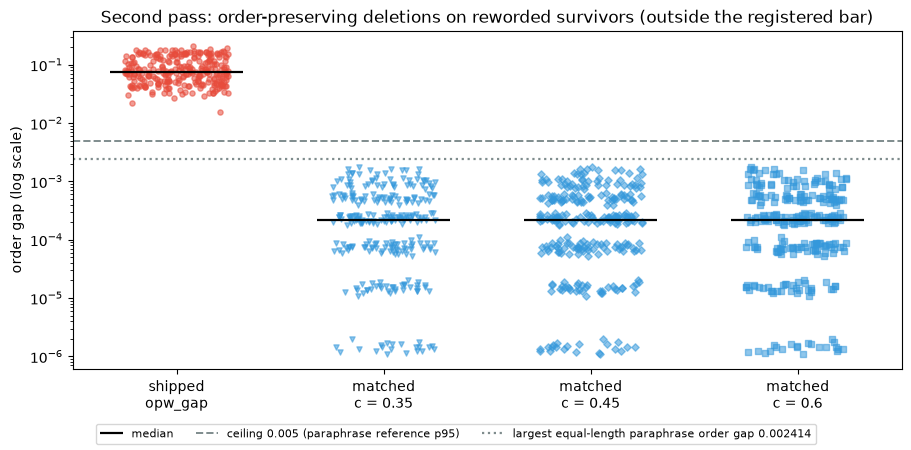

In [28]:
rng_plot = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(9, 4.4), constrained_layout=True)
columns = [("shipped", "shipped\nopw_gap", COL_SHIPPED, "o")] + [
    (f"matched_{tag(c)}", f"matched\nc = {c}", COL_MATCHED, marker) for c, marker in zip(CUTOFFS, ("v", "D", "s"))
]
for position, (column, label, colour, marker) in enumerate(columns):
    values = rw_df[column].drop_nans().to_numpy()
    ax.scatter(position + rng_plot.uniform(-0.25, 0.25, len(values)), np.maximum(values, PLOT_FLOOR), s=14, alpha=0.55, color=colour, marker=marker)
    ax.hlines(np.median(values), position - 0.32, position + 0.32, color="black", lw=1.6, label="median" if position == 0 else None)
ax.axhline(GAP_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"ceiling {GAP_BAR} (paraphrase reference p95)")
ax.axhline(PARA_GAP_MAX, color=COL_REFERENCE, ls=":", lw=1.6, label=f"largest equal-length paraphrase order gap {PARA_GAP_MAX:.6f}")
ax.set_yscale("log")
ax.set_xticks(range(len(columns)), [label for _, label, _, _ in columns])
ax.set_ylabel("order gap (log scale)")
ax.set_title("Second pass: order-preserving deletions on reworded survivors (outside the registered bar)")
fig.legend(fontsize=8, loc="outside lower center", ncol=3)
plt.show()

## Third pass - repeated statements and document length (outside the registered bar)

The registered deletion set cannot show two properties of the lever. The 10 base documents hold no repeated
statement, so the zero-cost assignment is unique and the matching returns the survivors by construction. They also
hold 11 to 14 statements, so the kill-gate reads the identity floor at those lengths only. This pass repeats the
order-preserving deletion on the one long document of the structure fixture, `source` (the ibm source article as
the fixture segments it; several of its statements are the list marker `-`), in two arms: the document with its
repeated statements kept, and the document with every repeated statement removed. Each arm takes prefixes of
increasing length and deletes 2 interior statements, 20 draws per length, with the draw seeds of the stage A
verifier probe that first measured the effect. The record registers no bar for this pass and it does not enter the
verdict.

The first cell reads the repeated statements and the identity floor `opw_gap(P, P)` of every prefix `P`.

In [29]:
long_texts = STATEMENTS[LONG_DOC]["statements"]
long_counts = Counter(long_texts)
REPEATED_TEXTS = {text: n for text, n in long_counts.items() if n > 1}
REPEATED_POSITIONS = [i for i, text in enumerate(long_texts) if long_counts[text] > 1]
unique_positions = [i for i, text in enumerate(long_texts) if long_counts[text] == 1]
ARM_KEPT, ARM_REMOVED = "repeated statements kept", "repeated statements removed"
LONG_ARMS = {ARM_KEPT: EMB[LONG_DOC], ARM_REMOVED: EMB[LONG_DOC][unique_positions]}


def prefix_lengths(doc: np.ndarray) -> tuple[int, ...]:
    """The configured prefix lengths below the document length, then the document length itself."""
    return (*(p for p in LONG_PREFIXES if p < len(doc)), len(doc))


def identity_gap(doc: np.ndarray) -> float:
    """``opw_gap(B, B)`` with both arguments the same object, as the kill-gate reads it."""
    return opw_gap(doc, doc)


FLOOR = {arm: {n: identity_gap(doc[:n]) for n in prefix_lengths(doc)} for arm, doc in LONG_ARMS.items()}
FLOOR_FIRST_ABOVE = {arm: next((n for n, gap in FLOOR[arm].items() if gap > GAP_BAR), None) for arm in LONG_ARMS}

t = Table(title=f"Third pass - identity floor opw_gap(P, P) of the prefixes of '{LONG_DOC}'", header_style="bold medium_purple")
for column in ("arm", "prefix length", "opw_gap(P, P)", f"share of the ceiling {GAP_BAR}", "above the ceiling"):
    t.add_column(column, justify="left" if column == "arm" else "right")
for arm in LONG_ARMS:
    for n, gap in FLOOR[arm].items():
        t.add_row(arm, str(n), f"{gap:.3e}", f"{gap / GAP_BAR:.2%}", "yes" if gap > GAP_BAR else "no")
console.print(Group(t,
    f"[bold]'{LONG_DOC}': {len(long_texts)} statements, {len(REPEATED_POSITIONS)} of them carry a repeated text[/bold] - "
    + "; ".join(f"{text!r} x{n} at positions {[i for i in REPEATED_POSITIONS if long_texts[i] == text]}" for text, n in REPEATED_TEXTS.items())
    + f"\nwith the repeated statements removed: {len(unique_positions)} statements, {repeated_count(long_texts[i] for i in unique_positions)} repeated\n"
    f"registered documents: {REPEATED_IN_BASES} repeated statements in the 10 base documents, {REPEATED_IN_PARAPHRASES} in their 10 paraphrases\n"
    f"kill-gate reading for comparison: max {KILL_GATE_MAX:.3e} on documents of {GATE_N_MIN} to {GATE_N_MAX} statements\n"
    "smallest measured prefix whose identity floor is above the ceiling: "
    + "; ".join(f"{arm} - {FLOOR_FIRST_ABOVE[arm] or 'none'}" for arm in LONG_ARMS)))

                     Third pass - identity floor opw_gap(P, P) of the prefixes of 'source'                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ arm                         ┃ prefix length ┃ opw_gap(P, P) ┃ share of the ceiling 0.005 ┃ above the ceiling ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ repeated statements kept    │            14 │     1.359e-04 │                      2.72% │                no │
│ repeated statements kept    │            20 │     1.279e-03 │                     25.59% │                no │
│ repeated statements kept    │            30 │     2.358e-03 │                     47.17% │                no │
│ repeated statements kept    │            40 │     3.340e-03 │                     66.80% │                no │
│ repeated statements kept    │            50 │     4.389e-03 │                     87.79% │                no │
│ repeated statements kept    │            62 │     4.607e-03 │                     92.14% │                no │
│ repeated statements removed │            14 │     6.667e-04 │                     13.33% │                no │
│ repeated statements removed │            20 │     2.562e-03 │                     51.24% │                no │
│ repeated statements removed │            30 │     5.182e-03 │                    103.64% │               yes │
│ repeated statements removed │            40 │     6.164e-03 │                    123.27% │               yes │
│ repeated statements removed │            50 │     6.635e-03 │                    132.71% │               yes │
│ repeated statements removed │            53 │     6.786e-03 │                    135.72% │               yes │
└─────────────────────────────┴───────────────┴───────────────┴────────────────────────────┴───────────────────┘
'source': 62 statements, 9 of them carry a repeated text - '-' x9 at positions [4, 6, 8, 21, 23, 26, 35, 40, 51]
with the repeated statements removed: 53 statements, 0 repeated
registered documents: 0 repeated statements in the 10 base documents, 0 in their 10 paraphrases
kill-gate reading for comparison: max 8.583e-04 on documents of 11 to 14 statements
smallest measured prefix whose identity floor is above the ceiling: repeated statements kept - none; repeated 
statements removed - 30

In [30]:
repeated_set = set(REPEATED_POSITIONS)
long_rows = []
for arm, doc in LONG_ARMS.items():
    for n in prefix_lengths(doc):
        A = doc[:n]
        for rep in range(LONG_REPS):
            drop = delete_positions(n, LONG_K, "interior", np.random.default_rng([LONG_SEED, n, rep]))
            keep = [i for i in range(n) if i not in drop]
            B = A[keep]
            rows, cols = match_statements(A, B, C_REGISTERED)
            long_rows.append({
                "arm": arm, "n": n, "rep": rep, "drop": drop,
                "dropped_repeated": bool(arm == ARM_KEPT and repeated_set.intersection(drop)),
                "unmatched": sorted(set(range(n)) - set(rows.tolist())),
                "recovered": survivors_recovered(rows, cols, keep),
                "shipped": opw_gap(A, B),
                "matched": matched_opw_gap(A, B, C_REGISTERED)[0],
                "floor": opw_gap(B, B.copy()),      # the reading an exact matching returns: the shortened document against its copy
            })
long_df = pl.DataFrame(long_rows)


def long_summary(frame: pl.DataFrame) -> dict:
    """Counts and extremes of one group of third-pass cases."""
    above_bar = frame["matched"] > GAP_BAR
    return {
        "cases": frame.height, "recovered": int(frame["recovered"].sum()),
        "matched_equal_to_floor": int((frame["matched"] == frame["floor"]).sum()),
        "above_bar": int(above_bar.sum()), "above_bar_recovered": int((above_bar & frame["recovered"]).sum()),
        "above_shipped": int((frame["matched"] > frame["shipped"]).sum()),
        "shipped_median": float(frame["shipped"].median()), "matched_median": float(frame["matched"].median()),
        "matched_max": float(frame["matched"].max()), "floor_max": float(frame["floor"].max()),
    }


LONG = {arm: long_summary(long_df.filter(pl.col("arm") == arm)) for arm in LONG_ARMS}
LONG_PER_N = {arm: {n: long_summary(long_df.filter((pl.col("arm") == arm) & (pl.col("n") == n))) for n in prefix_lengths(doc)}
              for arm, doc in LONG_ARMS.items()}
kept_df = long_df.filter(pl.col("arm") == ARM_KEPT)
DROPPED_REPEATED = int(kept_df["dropped_repeated"].sum())
NOT_RECOVERED_DROPPED_REPEATED = int((kept_df["dropped_repeated"] & ~kept_df["recovered"]).sum())
NOT_RECOVERED_OTHER = int((~kept_df["dropped_repeated"] & ~kept_df["recovered"]).sum())
worst = kept_df.sort("matched", descending=True).row(0, named=True)

tables = []
for arm in LONG_ARMS:
    t = Table(title=f"Third pass - k={LONG_K} interior deletions on prefixes of '{LONG_DOC}', {arm} (c = {C_REGISTERED})", header_style="bold medium_purple")
    for column in ("prefix length", "survivors recovered", "matched = floor", f"matched > {GAP_BAR}", "of which recovered",
                   "matched > shipped", "shipped median", "matched median", "matched max"):
        t.add_column(column, justify="right")
    for label, row in [*((str(n), row) for n, row in LONG_PER_N[arm].items()), ("all", LONG[arm])]:
        t.add_row(label, f"{row['recovered']}/{row['cases']}", f"{row['matched_equal_to_floor']}/{row['cases']}",
                  f"{row['above_bar']}/{row['cases']}", str(row["above_bar_recovered"]), f"{row['above_shipped']}/{row['cases']}",
                  f"{row['shipped_median']:.5f}", f"{row['matched_median']:.3e}", f"{row['matched_max']:.3e}",
                  style="bold" if label == "all" else None)
    tables.append(t)
console.print(Group(*tables,
    f"[bold]{ARM_KEPT}[/bold]: {DROPPED_REPEATED} of {LONG[ARM_KEPT]['cases']} deletions removed a repeated statement; the matching did not recover the"
    f" survivors in {NOT_RECOVERED_DROPPED_REPEATED} of those {DROPPED_REPEATED} and in {NOT_RECOVERED_OTHER} of the other"
    f" {LONG[ARM_KEPT]['cases'] - DROPPED_REPEATED}\n"
    f"largest reading: prefix {worst['n']}, deleted positions {worst['drop']}, statements of A left unmatched {worst['unmatched']} -"
    f" matched {worst['matched']:.4f}, shipped {worst['shipped']:.4f}, identity gap of the shortened document {worst['floor']:.3e}\n"
    f"[bold]{ARM_REMOVED}[/bold]: survivors recovered in {LONG[ARM_REMOVED]['recovered']}/{LONG[ARM_REMOVED]['cases']} cases;"
    f" matched above {GAP_BAR} in {LONG[ARM_REMOVED]['above_bar']}, all {LONG[ARM_REMOVED]['above_bar_recovered']} with the survivors recovered;"
    f" largest matched reading {LONG[ARM_REMOVED]['matched_max']:.3e}, largest identity gap of a shortened document {LONG[ARM_REMOVED]['floor_max']:.3e}\n"
    "[dim]'survivors recovered' = the matching pairs every surviving statement with its own copy; 'matched = floor' = the matched gap is exactly"
    " the identity order gap of the shortened document against its copy; 'of which recovered' = cases above the ceiling although the matching is"
    " exact[/dim]"))

          Third pass - k=2 interior deletions on prefixes of 'source', repeated statements kept (c = 0.6)          
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃     prefix ┃  survivors ┃  matched = ┃ matched > ┃   of which ┃ matched > ┃    shipped ┃   matched ┃    matched ┃
┃     length ┃  recovered ┃      floor ┃     0.005 ┃  recovered ┃   shipped ┃     median ┃    median ┃        max ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩
│         14 │      14/20 │      14/20 │      1/20 │          0 │      0/20 │    0.04870 │ 6.459e-05 │  2.807e-02 │
│         20 │      18/20 │      18/20 │      0/20 │          0 │      0/20 │    0.04250 │ 9.533e-04 │  1.999e-03 │
│         30 │      13/20 │      13/20 │      5/20 │          0 │      5/20 │    0.03780 │ 2.134e-03 │  3.246e-01 │
│         40 │      10/20 │      10/20 │     10/20 │          0 │     10/20 │    0.03834 │ 3.183e-02 │  1.006e-01 │
│         50 │      16/20 │      16/20 │      4/20 │          0 │      3/20 │    0.03224 │ 4.178e-03 │  7.615e-02 │
│         62 │      17/20 │      17/20 │      3/20 │          0 │      3/20 │    0.02916 │ 4.557e-03 │  6.406e-02 │
│        all │     88/120 │     88/120 │    23/120 │          0 │    21/120 │    0.03694 │ 3.211e-03 │  3.246e-01 │
└────────────┴────────────┴────────────┴───────────┴────────────┴───────────┴────────────┴───────────┴────────────┘
        Third pass - k=2 interior deletions on prefixes of 'source', repeated statements removed (c = 0.6)         
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃     prefix ┃  survivors ┃  matched = ┃ matched > ┃   of which ┃ matched > ┃    shipped ┃   matched ┃    matched ┃
┃     length ┃  recovered ┃      floor ┃     0.005 ┃  recovered ┃   shipped ┃     median ┃    median ┃        max ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━┩
│         14 │      20/20 │      20/20 │      0/20 │          0 │      0/20 │    0.09560 │ 2.604e-04 │  3.194e-04 │
│         20 │      20/20 │      20/20 │      0/20 │          0 │      0/20 │    0.05614 │ 1.827e-03 │  2.017e-03 │
│         30 │      20/20 │      20/20 │      3/20 │          3 │      0/20 │    0.04175 │ 4.731e-03 │  5.168e-03 │
│         40 │      20/20 │      20/20 │     20/20 │         20 │      0/20 │    0.03547 │ 5.852e-03 │  6.506e-03 │
│         50 │      20/20 │      20/20 │     20/20 │         20 │      0/20 │    0.03256 │ 6.286e-03 │  7.047e-03 │
│         53 │      20/20 │      20/20 │     20/20 │         20 │      0/20 │    0.03156 │ 6.616e-03 │  7.035e-03 │
│        all │    120/120 │    120/120 │    63/120 │         63 │     0/120 │    0.04129 │ 5.318e-03 │  7.047e-03 │
└────────────┴────────────┴────────────┴───────────┴────────────┴───────────┴────────────┴───────────┴────────────┘
repeated statements kept: 43 of 120 deletions removed a repeated statement; the matching did not recover the 
survivors in 32 of those 43 and in 0 of the other 77
largest reading: prefix 30, deleted positions [4, 6], statements of A left unmatched [23, 26] - matched 0.3246, 
shipped 0.0587, identity gap of the shortened document 2.926e-03
repeated statements removed: survivors recovered in 120/120 cases; matched above 0.005 in 63, all 63 with the 
survivors recovered; largest matched reading 7.047e-03, largest identity gap of a shortened document 7.047e-03
'survivors recovered' = the matching pairs every surviving statement with its own copy; 'matched = floor' = the 
matched gap is exactly the identity order gap of the shortened document against its copy; 'of which recovered' = 
cases above the ceiling although the matching is exact

The figure shows every third-pass case under the shipped order gap (circles) and under the matched order gap
(squares; hollow when the matching did not recover the survivors), per prefix length, with the identity floor of
the prefix (crosses) and the registered ceiling (dashed). The reading to check is which squares lie above the
ceiling, and whether they are hollow or follow the floor.

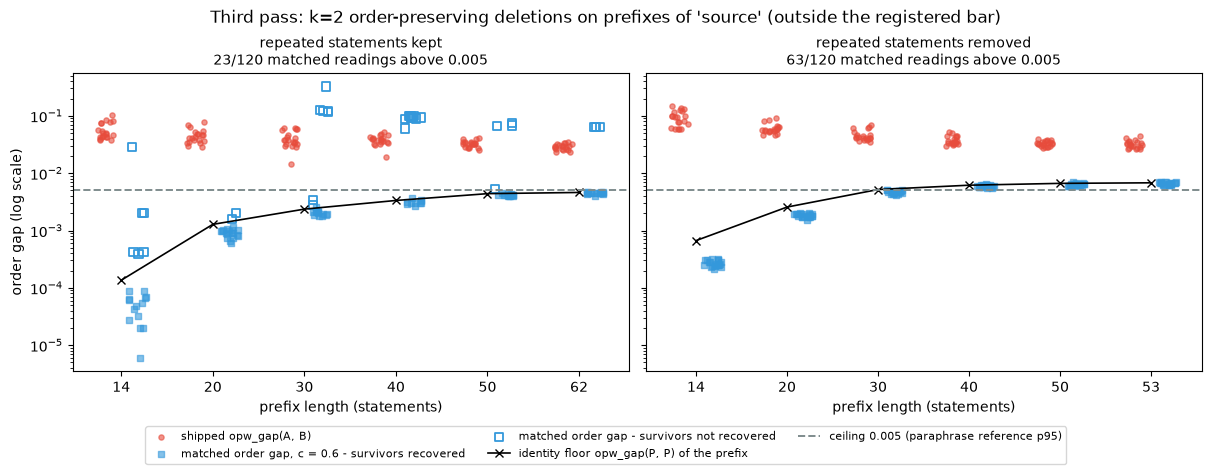

In [31]:
rng_plot = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True, sharey=True)
for ax, (arm, doc) in zip(axes, LONG_ARMS.items()):
    lengths = prefix_lengths(doc)
    sub = long_df.filter(pl.col("arm") == arm)
    x = np.array([lengths.index(n) for n in sub["n"].to_list()], dtype=float)
    recovered = sub["recovered"].to_numpy()
    matched = np.maximum(sub["matched"].to_numpy(), PLOT_FLOOR)
    matched_x = x + 0.18 + rng_plot.uniform(-0.1, 0.1, len(x))
    ax.scatter(x - 0.18 + rng_plot.uniform(-0.1, 0.1, len(x)), sub["shipped"].to_numpy(), s=14, alpha=0.6, color=COL_SHIPPED, marker="o",
               label="shipped opw_gap(A, B)")
    ax.scatter(matched_x[recovered], matched[recovered], s=14, alpha=0.6, color=COL_MATCHED, marker="s",
               label=f"matched order gap, c = {C_REGISTERED} - survivors recovered")
    ax.scatter(matched_x[~recovered], matched[~recovered], s=34, facecolors="none", edgecolors=COL_MATCHED, marker="s", lw=1.3,
               label="matched order gap - survivors not recovered")
    ax.plot(range(len(lengths)), list(FLOOR[arm].values()), color="black", marker="x", lw=1.2,
            label="identity floor opw_gap(P, P) of the prefix")
    ax.axhline(GAP_BAR, color=COL_REFERENCE, ls="--", lw=1.4, label=f"ceiling {GAP_BAR} (paraphrase reference p95)")
    ax.set_yscale("log")
    ax.set_xticks(range(len(lengths)), [str(n) for n in lengths])
    ax.set_xlabel("prefix length (statements)")
    ax.set_title(f"{arm}\n{LONG[arm]['above_bar']}/{LONG[arm]['cases']} matched readings above {GAP_BAR}", fontsize=10)
axes[0].set_ylabel("order gap (log scale)")
fig.suptitle(f"Third pass: k={LONG_K} order-preserving deletions on prefixes of '{LONG_DOC}' (outside the registered bar)")
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=8, loc="outside lower center", ncol=3)
plt.show()

## Acceptance bar

The registered bar, applied literally: all three clauses at the registered cutoff `c = 0.6`. The verdict follows the
campaign vocabulary - a fired kill-gate reads `Killed-at-gate`, a failed sanity check `Blocked`, a lever that meets
its bar `Promoted`, a lever that misses it `Refuted`. The two prediction rows are not clauses of the bar. The panel
states the scope of the registered sets and the third-pass reading beside the verdict.

In [32]:
BAR_MET = bool(CLAUSE1_MET and CLAUSE2_MET and CLAUSE3_MET)
PREDICTION_DELETION_HELD = bool(MATCHED_MEDIAN_K2 <= GAP_BAR)
if not KILL_GATE_PASSED:
    VERDICT = "Killed-at-gate"
elif not SANITY_PASSED:
    VERDICT = "Blocked"
elif BAR_MET:
    VERDICT = "Promoted"
else:
    VERDICT = "Refuted"

t = Table(title="Registered acceptance bar - E13-H70", header_style="bold medium_purple")
for column in ("clause", "requirement", "reading", "met"):
    t.add_column(column)
t.add_row("kill-gate", f"opw_gap(B, B) <= {GAP_BAR} on all 10 bases", f"max {KILL_GATE_MAX:.3e}", "yes" if KILL_GATE_PASSED else "no")
t.add_row("sanity check", f"shipped median at k=2 reproduces {H62_MEDIAN_K2}", f"{SHIPPED_MEDIAN_K2:.6f}", "yes" if SANITY_PASSED else "no")
t.add_row("1 - deletions", f">= {DELETION_SHARE_BAR:.0%} of 280 read <= {GAP_BAR}", f"{DEL_WITHIN}/{del_df.height} = {DEL_SHARE:.4f}", "yes" if CLAUSE1_MET else "no")
t.add_row("2 - separation", f"AUC >= {AUC_BAR}", f"{AUC_MATCHED:.6f} ({N_NEG} against {N_POS})", "yes" if CLAUSE2_MET else "no")
t.add_row("3 - bit-identity", "np.array_equal on every eligible pair", f"{N_IDENTICAL}/{N_ELIGIBLE} exactly equal", "yes" if CLAUSE3_MET else "no")
t.add_row("prediction - deletions", f"median at k=2 falls to <= {GAP_BAR}", f"{SHIPPED_MEDIAN_K2:.6f} → {MATCHED_MEDIAN_K2:.3e}", "yes" if PREDICTION_DELETION_HELD else "no")
t.add_row("prediction - rungs", "reordered-and-deleted cases stay near their rung",
          f"{RUNGS_RETAINED}/{RUNGS_TESTED} rungs under the executor rule, {RUNGS_NEAREST_OWN}/{RUNGS_TESTED} under the nearest-median rule",
          f"{'yes' if RUNG_HELD_EXECUTOR_RULE else 'no'} (executor rule), {'yes' if RUNG_HELD_NEAREST_MEDIAN else 'no'} (nearest-median rule)")
verdict_colour = "dark_sea_green" if VERDICT == "Promoted" else "indian_red"
console.print(Group(t, Panel(
    f"[bold {verdict_colour}]bar met: {BAR_MET} | verdict: {VERDICT}[/bold {verdict_colour}]\n"
    f"scope of the registered sets: documents of {GATE_N_MIN} to {GATE_N_MAX} statements with {REPEATED_IN_BASES} repeated statements\n"
    f"outside the bar, third pass on '{LONG_DOC}' (k={LONG_K} interior deletions): with the repeated statements kept the matched gap is"
    f" above the shipped gap in {LONG[ARM_KEPT]['above_shipped']}/{LONG[ARM_KEPT]['cases']} cases and above {GAP_BAR} in"
    f" {LONG[ARM_KEPT]['above_bar']}/{LONG[ARM_KEPT]['cases']}; with them removed it is above {GAP_BAR} in"
    f" {LONG[ARM_REMOVED]['above_bar']}/{LONG[ARM_REMOVED]['cases']} cases, {LONG[ARM_REMOVED]['above_bar_recovered']} of them with the survivors recovered",
    border_style=verdict_colour, expand=False)))

                                        Registered acceptance bar - E13-H70                                        
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ clause                 ┃ requirement                 ┃ reading                     ┃ met                        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ kill-gate              │ opw_gap(B, B) <= 0.005 on   │ max 8.583e-04               │ yes                        │
│                        │ all 10 bases                │                             │                            │
│ sanity check           │ shipped median at k=2       │ 0.134041                    │ yes                        │
│                        │ reproduces 0.134            │                             │                            │
│ 1 - deletions          │ >= 95% of 280 read <= 0.005 │ 280/280 = 1.0000            │ yes                        │
│ 2 - separation         │ AUC >= 0.95                 │ 0.999903 (70 against 10010) │ yes                        │
│ 3 - bit-identity       │ np.array_equal on every     │ 1847/1847 exactly equal     │ yes                        │
│                        │ eligible pair               │                             │                            │
│ prediction - deletions │ median at k=2 falls to <=   │ 0.134041 → 9.671e-05        │ yes                        │
│                        │ 0.005                       │                             │                            │
│ prediction - rungs     │ reordered-and-deleted cases │ 5/5 rungs under the         │ yes (executor rule), no    │
│                        │ stay near their rung        │ executor rule, 4/5 under    │ (nearest-median rule)      │
│                        │                             │ the nearest-median rule     │                            │
└────────────────────────┴─────────────────────────────┴─────────────────────────────┴────────────────────────────┘
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ bar met: True | verdict: Promoted                                                                               │
│ scope of the registered sets: documents of 11 to 14 statements with 0 repeated statements                       │
│ outside the bar, third pass on 'source' (k=2 interior deletions): with the repeated statements kept the matched │
│ gap is above the shipped gap in 21/120 cases and above 0.005 in 23/120; with them removed it is above 0.005 in  │
│ 63/120 cases, 63 of them with the survivors recovered                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Guardrails

The standing guardrails, measured. `V` is the count of (gold, adversarial) pairs ranked in the wrong order by shipped
`smd` on the ibm panel, out of 24; the panel is built as in E12-H66 (title line dropped, shipped segmenter, shipped
INT8 encoder). The source tree is hashed again and compared with the opening digest, `git status` is read for
`src/` and `tests/`, and the default-path readings are compared by `np.array_equal`: the `(gold, gold-2)` pair and
the 280 shipped deletion readings, recomputed. Three rows can fail: `V`, the digest comparison and `git status`. The
two default-path rows compare two calls inside this kernel, and the metric-property row is a statement, not a test.

In [33]:
def load_body(path: Path) -> str:
    """Body text of a summary with the markdown title line removed (the E12-H66 panel loader)."""
    return "\n".join(line for line in path.read_text().splitlines() if not line.startswith("# ")).strip()


def state(ok: bool) -> str:
    """Rich-coloured guardrail state."""
    return "[dark_sea_green]hold[/dark_sea_green]" if ok else "[indian_red]BREACH[/indian_red]"


segmenter = Segmenter()
panel_emb = {label: ENC.encode(segmenter.split(load_body(SUMMARY_DIR / fname))) for fname, label, _ in PANEL_DOCS}
panel_dist = {label: smd(panel_emb[label], panel_emb[PANEL_REFERENCE]) for _, label, _ in PANEL_DOCS if label != PANEL_REFERENCE}
gold_labels = [label for _, label, tier in PANEL_DOCS if tier == "gold" and label != PANEL_REFERENCE]
adv_labels = [label for _, label, tier in PANEL_DOCS if tier != "gold"]
V = int(sum(1 for g in gold_labels for a in adv_labels if panel_dist[g] >= panel_dist[a]))
V_TOTAL = len(gold_labels) * len(adv_labels)
closeness_of = {label: max(0.0, 1.0 - d / SMD_MAX) for label, d in panel_dist.items()}
PANEL_MARGIN_PTS = (min(closeness_of[g] for g in gold_labels) - max(closeness_of[a] for a in adv_labels)) * 100

digest_after = {folder: tree_digest(folder) for folder in GUARD_FOLDERS}
SRC_UNTOUCHED = bool(digest_after == digest_before)
git_status = subprocess.run(["git", "status", "--porcelain", "src/", "tests/"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
guard_after = np.array([smd(EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]]), opw_gap(EMB[GUARD_PAIR[0]], EMB[GUARD_PAIR[1]])])
DEFAULT_PATH_EQUAL = bool(np.array_equal(guard_before, guard_after))
shipped_again = np.array([opw_gap(EMB[case["base"]], EMB[case["base"]][case["keep"]]) for case in CASES])
SHIPPED_280_EQUAL = bool(np.array_equal(shipped_deletion, shipped_again))

t = Table(title="Guardrails", header_style="bold medium_purple")
for column in ("guardrail", "reading", "state"):
    t.add_column(column)
t.add_row("V - content ordinality (ibm panel)", f"{V}/{V_TOTAL} violations, boundary margin {PANEL_MARGIN_PTS:+.2f} pts"
          f" (primer naive row: V {PANEL_PRIMER_ROW['V']}/24, margin {PANEL_PRIMER_ROW['margin_pts']:+.2f})", state(V == 0))
t.add_row("src/ and tests/ sha256 unchanged", ", ".join(f"{folder} {digest_after[folder][:16]}" for folder in GUARD_FOLDERS), state(SRC_UNTOUCHED))
t.add_row("git status src/ tests/", git_status or "(clean)", state(not git_status))
t.add_row(f"default path on {GUARD_PAIR}", f"smd {float(guard_after[0])!r}, order gap {float(guard_after[1])!r} - np.array_equal {DEFAULT_PATH_EQUAL}",
          state(DEFAULT_PATH_EQUAL))
t.add_row("280 shipped deletion readings recomputed", f"np.array_equal {SHIPPED_280_EQUAL}", state(SHIPPED_280_EQUAL))
t.add_row("metric property", "shipped opw_gap is a score (E11 triangle-violation rate 0.15) and is not edited; the matched gap is prototyped"
          " here and is a score; no triangle test was run on it", "[dim]stated, not tested[/dim]")
console.print(Group(t,
    "[dim]rows that can fail: V, the sha256 comparison and git status. The two default-path rows compare two calls of the unmodified shipped"
    " functions inside this kernel, so they detect a change made during this run only. The metric-property row is a statement.[/dim]"))

                                                    Guardrails                                                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ guardrail                                ┃ reading                                         ┃ state              ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ V - content ordinality (ibm panel)       │ 0/24 violations, boundary margin +4.71 pts      │ hold               │
│                                          │ (primer naive row: V 0/24, margin +4.71)        │                    │
│ src/ and tests/ sha256 unchanged         │ src be7e159f81c53284, tests 00ea6c7799307adb    │ hold               │
│ git status src/ tests/                   │ (clean)                                         │ hold               │
│ default path on ('gold', 'gold-2')       │ smd 0.22343884174015136, order gap              │ hold               │
│                                          │ 0.1343654387715936 - np.array_equal True        │                    │
│ 280 shipped deletion readings recomputed │ np.array_equal True                             │ hold               │
│ metric property                          │ shipped opw_gap is a score (E11                 │ stated, not tested │
│                                          │ triangle-violation rate 0.15) and is not        │                    │
│                                          │ edited; the matched gap is prototyped here and  │                    │
│                                          │ is a score; no triangle test was run on it      │                    │
└──────────────────────────────────────────┴─────────────────────────────────────────────────┴────────────────────┘
rows that can fail: V, the sha256 comparison and git status. The two default-path rows compare two calls of the 
unmodified shipped functions inside this kernel, so they detect a change made during this run only. The 
metric-property row is a statement.

## Metrics

Every measured number, the bar readings and the guardrail readings, written to
`reports/E13-H70-matched-order-gap-metrics.json`. The printed block is the set of numbers the stage A result quotes.

In [34]:
def sig(value: float, digits: int = 6) -> float:
    """``value`` at ``digits`` significant digits, so readings near 1e-7 keep their precision in JSON."""
    return float(f"{float(value):.{digits}g}")


def sig_values(row: dict) -> dict:
    """``row`` with every float at 6 significant digits."""
    return {key: (sig(value) if isinstance(value, float) else value) for key, value in row.items()}


metrics = {
    "id": "E13-H70",
    "slug": "matched-order-gap",
    "environment": {"python": sys.version.split()[0], "docdistance": docdistance.__version__, "pot": ot.__version__,
                    "numpy": np.__version__, "scipy": scipy.__version__, "encoder": "mmBERT OpenVINO INT8 (CPU)"},
    "seed": SEED,
    "kill_gate": {
        "call": "opw_gap(B, B) on the 10 base documents", "bar": GAP_BAR, "passed": KILL_GATE_PASSED,
        "max": sig(KILL_GATE_MAX), "max_second_argument_copied": sig(KILL_GATE_MAX_COPY),
        "n_statements_min": GATE_N_MIN, "n_statements_max": GATE_N_MAX,
        "per_base": {row["base"]: sig(row["identity_gap"]) for row in gate_df.iter_rows(named=True)},
        "per_base_second_argument_copied": {row["base"]: sig(row["identity_gap_copy"]) for row in gate_df.iter_rows(named=True)},
    },
    "sanity_check": {
        "passed": SANITY_PASSED, "n_cases": del_df.height, "tolerance": SANITY_TOL,
        "shipped_median_k2": sig(SHIPPED_MEDIAN_K2), "record_median_k2": H62_MEDIAN_K2, "saved_median_k2": h62_per_k["2"]["median"],
        "abs_dev_k2": sig(SANITY_DEV_K2), "max_abs_dev_12_saved_values": sig(SANITY_MAX_DEV),
        "shipped_above_bar": SHIPPED_ABOVE_BAR,
        "shipped_median_per_k": {str(row["k"]): sig(row["median_here"]) for row in sanity_df.iter_rows(named=True)},
    },
    "clause_1_deletions": {
        "cutoff": C_REGISTERED, "bar_share": DELETION_SHARE_BAR, "gap_bar": GAP_BAR, "met": CLAUSE1_MET,
        "within_bar": DEL_WITHIN, "n": del_df.height, "share": sig(DEL_SHARE), "recovered": DEL_RECOVERED, "no_matched_pair": DEL_NAN,
        "repeated_statements_in_base_documents": REPEATED_IN_BASES,
        "matched_median": sig(del_df[REG].median()), "matched_p95": sig(del_df[REG].quantile(0.95)), "matched_max": sig(del_df[REG].max()),
        "shipped_median": sig(del_df["shipped"].median()),
        "per_k": {str(row["k"]): {"n": row["n"], "shipped_median": sig(row["shipped_median"]), "matched_median": sig(row["matched_median"]),
                                  "matched_p95": sig(row["matched_p95"]), "matched_max": sig(row["matched_max"]), "within_bar": row["within_bar"]}
                  for row in per_k.iter_rows(named=True)},
    },
    "clause_2_separation": {
        "cutoff": C_REGISTERED, "bar_auc": AUC_BAR, "met": CLAUSE2_MET, "n_negatives": N_NEG, "n_positives": N_POS,
        "rung_min": RUNG_MIN, "displacement_min": sig(RUNG_EDGES[RUNG_MIN - 1]), "k": K_SEPARATION,
        "unique_permutations": len(POOL), "order_kept_positives": N_ORDER_KEPT,
        "order_kept_positives_at_or_below_bar": ORDER_KEPT_AT_OR_BELOW_BAR,
        "matched": {key: (sig(value) if isinstance(value, float) else value) for key, value in AUC_ROWS[REG].items() if key != "per_rung"}
                   | {"per_rung": {str(r): sig(v) for r, v in AUC_ROWS[REG]["per_rung"].items()}},
        "shipped": {key: (sig(value) if isinstance(value, float) else value) for key, value in AUC_ROWS["shipped"].items() if key != "per_rung"}
                   | {"per_rung": {str(r): sig(v) for r, v in AUC_ROWS["shipped"]["per_rung"].items()}},
    },
    "clause_3_bit_identity": {
        "cutoff": C_REGISTERED, "met": CLAUSE3_MET, "array_equal": BIT_IDENTICAL, "fixture_pairs": N_FIXTURE_PAIRS,
        "equal_length_pairs": N_EQUAL_LENGTH, "eligible_pairs": N_ELIGIBLE, "exactly_equal": N_IDENTICAL, "max_abs_diff": MAX_ABS_DIFF,
        "without_full_match_branch": {"exactly_equal": N_INDEXED_IDENTICAL, "max_abs_diff": sig(INDEXED_MAX_ABS_DIFF),
                                      "differing_families": INDEXED_DIFF_FAMILIES},
        "by_family": {row["family"]: {"pairs": row["pairs"], "equal_length": row["equal_length"], "eligible": row["eligible"], "identical": row["identical"]}
                      for row in by_family.iter_rows(named=True)},
        "unequal_length_pairs_outside_the_bar": {family: sig_values(row) for family, row in UNEQUAL.items()},
    },
    "prediction": {
        "deletion_median_k2_shipped": sig(SHIPPED_MEDIAN_K2), "deletion_median_k2_matched": sig(MATCHED_MEDIAN_K2),
        "deletion_part_held": PREDICTION_DELETION_HELD,
        "rung_rule_executor": "matched median strictly between the reorder-only medians of the adjacent rungs",
        "rung_rule_nearest_median": "the reorder-only median nearest to the matched median is the rung's own",
        "rungs_tested": RUNGS_TESTED,
        "rungs_retained_executor_rule": RUNGS_RETAINED, "rung_part_held_executor_rule": RUNG_HELD_EXECUTOR_RULE,
        "rungs_retained_nearest_median_rule": RUNGS_NEAREST_OWN, "rung_part_held_nearest_median_rule": RUNG_HELD_NEAREST_MEDIAN,
        "rungs_retained_shipped_medians_executor_rule": RUNGS_RETAINED_SHIPPED,
        "spearman_matched_vs_reorder_only": sig(SPEARMAN_REORDER),
        "per_rung": {str(row["rung"]): {"unique_perms": row["perms"], "cases": row["cases"], "reorder_only_median": sig(row["reorder_only"]),
                                        "shipped_after_deletion_median": sig(row["shipped_after_deletion"]),
                                        "matched_after_deletion_median": sig(row["matched_after_deletion"]), "ratio": sig(row["ratio"]),
                                        "nearest_rung": row["nearest_rung"], "retained": row["retained"],
                                        "shipped_retained": row["shipped_retained"],
                                        "induced_order_same_rung_share": sig(row["same_rung_after"])}
                     for row in rung_df.iter_rows(named=True)},
    },
    "sensitivity": {
        "inert_on_registered_sets": SENSITIVITY_INERT,
        "per_cutoff": {str(row["c"]): {"deletion_within_bar": row["deletion_within_bar"], "deletion_share": sig(row["deletion_share"]),
                                       "deletion_median_k2": sig(row["deletion_median_k2"]), "auc": sig(row["auc"]),
                                       "eligible_pairs": row["eligible_pairs"], "bit_identical": row["bit_identical"],
                                       "deletion_equal_to_registered": row["deletion_equal_to_registered"],
                                       "positives_equal_to_registered": row["positives_equal_to_registered"]}
                       for row in sens_df.iter_rows(named=True)},
    },
    "second_pass_reworded_deletions": {
        "in_bar": False, "n": rw_df.height, "paraphrase": "<base>~bt back-translation, per-statement reword of equal length",
        "aligned_statements": PARA_ALIGNED, "statements": PARA_STATEMENTS,
        "true_pair_cost_median": sig(np.median(TRUE_COSTS)), "true_pair_cost_max": sig(TRUE_COSTS.max()),
        "true_pairs_at_or_above_cutoff": {str(c): TRUE_AT_OR_ABOVE[c] for c in CUTOFFS},
        "equal_length_paraphrase_gap_median": sig(para_df["paraphrase_gap"].median()), "equal_length_paraphrase_gap_max": sig(PARA_GAP_MAX),
        "shipped": {key: (sig(value) if isinstance(value, float) else value) for key, value in RW["shipped"].items()},
        "per_cutoff": {str(c): {key: (sig(value) if isinstance(value, float) else value) for key, value in RW[c].items()} for c in CUTOFFS},
    },
    "third_pass_long_document": {
        "in_bar": False, "document": LONG_DOC, "statements": len(long_texts), "repeated_statements": len(REPEATED_POSITIONS),
        "repeated_texts": REPEATED_TEXTS, "repeated_positions": REPEATED_POSITIONS, "statements_after_removal": len(unique_positions),
        "k": LONG_K, "draws_per_length": LONG_REPS, "seed": f"[{LONG_SEED}, prefix length, draw]", "cutoff": C_REGISTERED,
        "registered_documents": {"repeated_statements_in_base_documents": REPEATED_IN_BASES,
                                 "repeated_statements_in_paraphrases": REPEATED_IN_PARAPHRASES,
                                 "n_statements_min": GATE_N_MIN, "n_statements_max": GATE_N_MAX},
        "deletions_that_removed_a_repeated_statement": DROPPED_REPEATED,
        "not_recovered_among_those": NOT_RECOVERED_DROPPED_REPEATED, "not_recovered_among_the_others": NOT_RECOVERED_OTHER,
        "largest_reading": {"prefix_length": worst["n"], "deleted_positions": worst["drop"], "unmatched_positions": worst["unmatched"],
                            "matched": sig(worst["matched"]), "shipped": sig(worst["shipped"]),
                            "identity_gap_of_shortened": sig(worst["floor"])},
        "arms": {arm: sig_values(LONG[arm]) | {
                     "smallest_prefix_with_identity_gap_above_bar": FLOOR_FIRST_ABOVE[arm],
                     "per_length": {str(n): {"identity_gap": sig(FLOOR[arm][n])} | sig_values(row) for n, row in LONG_PER_N[arm].items()}}
                 for arm in LONG_ARMS},
    },
    "acceptance": {
        "bar": ">= 95% of the 280 order-preserving deletion cases read <= 0.005 AND deleted-only against reordered-and-deleted AUC >= 0.95 "
               "AND np.array_equal with shipped opw_gap on every fully matched equal-length pair of the structure fixture",
        "clause_1_met": CLAUSE1_MET, "clause_2_met": CLAUSE2_MET, "clause_3_met": CLAUSE3_MET, "met": BAR_MET, "verdict": VERDICT,
    },
    "guardrails": {
        "V": f"{V}/{V_TOTAL}", "panel_margin_pts": round(PANEL_MARGIN_PTS, 4), "src_untouched": SRC_UNTOUCHED,
        "git_status_src_tests": git_status or "clean", "default_path_array_equal": DEFAULT_PATH_EQUAL,
        "shipped_280_array_equal": SHIPPED_280_EQUAL,
        "metric_property": "shipped opw_gap is a score (E11 triangle-violation rate 0.15) and is not edited; the matched gap is a notebook"
                           " prototype and a score; no triangle test was run on it",
        "rows_that_can_fail": "V, sha256 of src and tests, git status",
    },
}

In [35]:
METRICS_OUT.parent.mkdir(parents=True, exist_ok=True)
METRICS_OUT.write_text(json.dumps(metrics, indent=2) + "\n")
print(f"wrote {METRICS_OUT.relative_to(ROOT)} ({METRICS_OUT.stat().st_size} bytes)")
print(json.dumps({key: metrics[key] for key in ("kill_gate", "sanity_check", "clause_1_deletions", "clause_2_separation",
                                                "clause_3_bit_identity", "prediction", "sensitivity", "second_pass_reworded_deletions",
                                                "third_pass_long_document",
                                                "acceptance", "guardrails")}, indent=1))

wrote reports/E13-H70-matched-order-gap-metrics.json (21230 bytes)
{
 "kill_gate": {
  "call": "opw_gap(B, B) on the 10 base documents",
  "bar": 0.005,
  "passed": true,
  "max": 0.000858319,
  "max_second_argument_copied": 0.000860246,
  "n_statements_min": 11,
  "n_statements_max": 14,
  "per_base": {
   "gold": 0.000161551,
   "gold-2": 0.000537247,
   "v1": 0.000305484,
   "v2": 0.000356898,
   "opus": 0.000458514,
   "sonnet": 0.000186026,
   "haiku": 0.000858319,
   "werg-a": 0.000169275,
   "werg-b": 0.000380139,
   "werg-c": 0.000791582
  },
  "per_base_second_argument_copied": {
   "gold": 0.00016193,
   "gold-2": 0.000538595,
   "v1": 0.000306735,
   "v2": 0.000357705,
   "opus": 0.000459683,
   "sonnet": 0.000186462,
   "haiku": 0.000860246,
   "werg-a": 0.000169813,
   "werg-b": 0.000380833,
   "werg-c": 0.000793691
  }
 },
 "sanity_check": {
  "passed": true,
  "n_cases": 280,
  "tolerance": 0.0005,
  "shipped_median_k2": 0.134041,
  "record_median_k2": 0.134,
  "saved_me

## Conclusions

**Verdict: Promoted, within the scope of the registered sets.** The matched order gap at the registered cutoff
`c = 0.6` meets all three clauses of the registered bar, after the kill-gate passed and the harness reproduced the
E12-H62 reading. The registered sets hold documents of 11 to 14 statements with 0 repeated statements. The third
pass measures two limits outside that scope, on the one long fixture document: with repeated statements the matched
gap reads above the shipped gap in 21 of 120 cases, and with the repeated statements removed the identity floor of
shipped `opw_gap` is itself above the ceiling `0.005` from 30 statements.

**Gate and harness**

- **Kill-gate passed** - the largest `opw_gap(B, B)` over the 10 base documents is `8.583e-04` (haiku), `17.17%` of the ceiling `0.005`; with the second argument passed as a copy the largest value is `8.602e-04`. The gate covers lengths of 11 to 14 statements only
- **Sanity check passed** - the rebuilt set has 280 cases and its shipped median at `k=2` is `0.134041`, at `1.3e-07` from the saved E12-H62 value; the largest deviation over the 12 saved median, min and max values is `4.9e-07`; 280 of 280 shipped readings are above `0.005`

**Clause 1 - deletions: met, 280/280 against a bar of 95%**

- **Reading** - every one of the 280 order-preserving deletion cases reads `≤ 0.005`; the largest matched reading is `6.101e-04` and the median at `k=2` falls from `0.134041` to `9.671e-05`
- **Mechanism** - the matching returns exactly the surviving statements in 280 of 280 cases, so the matched gap is the order gap of the shortened document against a copy of itself. That is the identity floor the kill-gate measures. The floor grows with document length (`1.616e-04` at 11 statements, `8.583e-04` at 14), which is why the matched median falls as `k` rises (`2.056e-04` at `k=1`, `9.266e-06` at `k=4`)
- **Meaning** - on this set clause 1 holds by construction once the matching is correct. The surviving statements are byte-identical, so the clause does not measure robustness to rewording; the second pass measures that. The 10 base documents hold 0 repeated statements, so the zero-cost assignment is unique and the count 280 of 280 has one possible value; the third pass measures a document where it can move

**Clause 2 - separation: met, AUC 0.999903 against a bar of 0.95**

- **Reading** - 70 deleted-only cases against 10010 reordered-and-deleted cases separate at AUC `0.999903`. The largest deleted-only reading is `3.632e-04`; the smallest reading of a positive that still carries a reorder is `0.050753`
- **The one overlap** - 1 of 10010 positives reads `1.737e-05`. Its deletion removed the displaced statements, its survivors are in original order, and the low reading is the correct one. Without it the AUC is `1.000000`
- **Baseline** - the shipped order gap reads AUC `0.950980` on the same classes, which is above the bar as well. The pooled AUC clause therefore does not separate the lever from the baseline. The per-rung reading does: rung 2 `0.818067` → `0.999490`, rung 3 `0.945022` → `1.000000`
- **As a decision at the ceiling** - under the matched gap 0 of 70 deleted-only cases read above `0.005`; under the shipped gap 70 of 70 do

**Clause 3 - bit-identity: met, 1847/1847**

- **Reading** - of the 1913 pairs the fixture defines, 1847 have equal length and all 1847 are fully matched at `c = 0.6`. The matched gap equals shipped `opw_gap` exactly on all of them, largest difference `0.0`
- **Mechanism** - the equality holds by construction: `matched_opw_gap` passes a fully matched equal-length pair to `opw_gap` unmodified. Without that branch 1837 of 1847 are equal. The 10 that differ, by at most `2.108e-06`, are the identity pairs: POT sets the diagonal of the ground cost to zero only when both arguments are the same object
- **Impact** - a build of this lever needs the full-match branch to keep the shipped values bit-identical
- **Coverage** - 1820 of the 1847 eligible pairs are reorder-pool entries; 27 come from the other families
- **The 66 pairs of unequal length, outside the bar** - the matched gap reads below the shipped gap in 42 pairs and above it in 24; the median moves from `0.0438` to `0.0200`; 22 pairs read `≤ 0.005` against 0 under the shipped gap; the largest matched reading is `0.1621`; every statement of the shorter document is matched in 59 of 66 pairs. No ground truth exists for these pairs, so this is a reading and not a test

**Prediction**

- **Deletion half held** - median at `k=2` `0.134041` → `9.671e-05`, predicted `≤ 0.005`
- **Rung half - 5 of 5 rungs under the executor rule, 4 of 5 under the nearest-median rule** - the matched medians after the deletion are `0.20454`, `0.30459`, `0.37089`, `0.40532`, `0.42541` for rungs 2 to 6, against reorder-only medians `0.15524`, `0.25920`, `0.34850`, `0.40234`, `0.42441`. The rung that fails the nearest-median rule is rung 3: its matched median is nearer to the rung-4 reorder-only median
- **Standing of the two rules** - the record gives no number for "near its reorder rung". Both rules were written by the executor, and the repository does not prove that either was chosen before the readings were seen. The executor rule is wide. It can fail: applied to the shipped medians after the deletion it retains 3 of 5 rungs
- **Size of the departure** - the matched median is above the reorder-only median by a factor of `1.318` at rung 2, falling to `1.002` at rung 6. The deletion itself changes the order of the survivors: at rung 2, `75.1%` of the cases still sit in the rung of their permutation
- **Against the shipped reading** - after the deletion the shipped gap reads `0.34148` and `0.35830` at rungs 5 and 6, below the reorder-only medians; the matched gap reads `0.40532` and `0.42541`. Rank agreement between the matched gap and the reorder-only gap of the same permutation: Spearman `0.8058`

**Cutoff sensitivity and the second pass**

- **The cutoff is inert on the registered sets** - at `c = 0.35`, `0.45` and `0.6` the per-case readings are exactly equal on the 280 deletion cases and on the 10010 positives. Only the number of eligible clause-3 pairs changes: `1840`, `1845`, `1847`
- **The lever holds on reworded survivors** - with the survivors replaced by their back-translation, 280 of 280 cases read `≤ 0.005` (median `0.000218`, max `0.001752`, below the largest equal-length paraphrase gap `0.002414`), against 0 of 280 for the shipped gap (median `0.076387`). Every matched pair joins a statement with its own reword in 280 of 280 cases
- **The cutoff is inert there as well** - all 124 true pairs cost less than `0.35` (median `0.154685`, max `0.322901`). In a pure deletion the removed statements stay unmatched because the shorter document has no free statement, not because of the cutoff
- **Meaning** - this experiment gives no evidence for or against the value `0.6`. The cutoff can act only when both documents hold statements without a counterpart (a substitution, or insertions on both sides), and no case of that kind is in the registered sets or in the second pass

**Third pass - two limits outside the registered scope**

- **Set** - the fixture document `source` holds 62 statements; 9 of them are the text `-` (positions 4, 6, 8, 21, 23, 26, 35, 40, 51). With those 9 removed it holds 53 statements and 0 repeated. Each arm: 6 prefix lengths, 20 draws of 2 interior deletions, 120 cases
- **Limit 1, repeated statements - the matching is not unique** - with the repeated statements kept the matching recovers the survivors in 88 of 120 cases. 43 of the 120 deletions removed a repeated statement; the matching failed in 32 of those 43 and in 0 of the other 77. The matched gap reads above `0.005` in 23 of 120 cases, none of them with the survivors recovered, and above the shipped gap in 21 of 120. Largest reading: prefix 30, deleted positions 4 and 6, the matching left positions 23 and 26 unmatched - matched `0.3246` against shipped `0.0587`
- **Cause** - identical statements have identical cost rows, so the assignment has ties. It can pair a `-` of the shortened document with a `-` that was deleted and leave a surviving `-` unmatched; the two matched sub-sequences then differ by moved statements. The lever reads that move as a reorder
- **Limit 2, document length - the identity floor crosses the ceiling** - with the repeated statements removed the matching recovers the survivors in 120 of 120 cases and the matched gap equals the identity order gap of the shortened document in 120 of 120. It is above `0.005` in 63 of 120 cases (0, 0, 3, 20, 20, 20 of 20 at prefix lengths 14, 20, 30, 40, 50, 53) and above the shipped gap in 0 of 120. The cause is the floor of shipped `opw_gap`: `opw_gap(P, P)` reads `2.562e-03` at 20 statements, `5.182e-03` at 30 and `6.786e-03` at 53. The kill-gate condition (identity floor above `0.005`) is met in this arm from 30 statements; with the repeated statements kept the floor reads `4.607e-03` at 62 statements and stays below the ceiling
- **What the lever still does there** - in the arm without repeated statements the shipped median is `0.04129` and the matched median `5.318e-03`: the lever removes most of the deletion reading and returns the identity floor
- **Standing** - one document, no registered bar, not a held-out measurement. It reproduces the stage A verifier probe (88 of 120, 23 of 120, 21 of 120, `0.3246`) and adds the arm without repeated statements

**Guardrails hold, measured**

- `V = 0/24` on the ibm panel, boundary margin `+4.71` points, equal to the naive row the campaign primer quotes
- `src/` and `tests/` digests are unchanged and `git status` is clean for both
- Default-path `smd` and `opw_gap` on `(gold, gold-2)` and the 280 shipped deletion readings are equal under `np.array_equal` before and after. These two rows compare two calls inside one kernel, so they detect a change made during the run only
- Metric property: `opw_gap` is a score and the matched gap is a score. This row is a statement; no triangle test was run

**What this warrants and what it does not**

- **Warranted** - the registered bar is met. On documents of 11 to 14 statements with no repeated statement the matched order gap removes the deletion reading (`0.134041` → `9.671e-05` at `k=2`) and keeps the order of the reorder rungs (5 of 5 under the executor rule, 4 of 5 under the nearest-median rule)
- **Not warranted** - a reading at or below `0.005` on every order-preserving deletion. Measured in the third pass: with repeated statements the prototype reads above the shipped gap in 21 of 120 cases, and with the repeated statements removed the identity floor alone is above `0.005` from 30 statements
- **Deferred to the build** - a held-out measurement of the deletion clause on documents with repeated statements and on documents above 14 statements. A tie-break rule for the matching and a length-dependent ceiling are new mechanisms; neither is part of the registered lever and neither was added here
- **Not shown** - the value of `c`; the reading under insertions and substitutions; the reading when a reword costs more than the cutoff; near-identical statements that are not byte-identical; a triangle test of the new reading; a ground truth for the 66 pairs of unequal length
- **Executor readings of the record** - "rung 2 or above" is displacement `≥ 1/6` (the E11 bins); the positive class deletes positions of the reordered document; the section-swap family enters clause 3 as 10 identity pairs; the two rules for "near its rung" and the sanity tolerance `0.0005` were written by the executor because the record gives no number